In [ ]:
#IMPORTS
'''import DataHandling as DH
import matplotlib.pyplot as plt
import utils as utl
import numpy as np
import Preprocessing as pre'''
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import DataHandling as DH
import Preprocessing as pre
import utils as utl
from datetime import datetime, timedelta
import os

# Set the base directory where JSON files are located
base_directory = "C:\\Users\\OCD\\Desktop\\DATA\\RN"  # Change this to your folder path

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-11-11\\Report_Json_Session_Report_20241125T163059.json"

Data = DH.getData(file_path)

## save table in csv and txt

In [ ]:
import dearpygui.dearpygui as dpg
import csv

dpg.create_context()

def save_table_to_file(sender, app_data, user_data):
    """Saves DPG table data to a .csv or .txt file"""
    table_id, file_type = user_data  # Unpack table ID and file type



    # Get table columns (headers)
    column_children = dpg.get_item_children(table_id, slot=0)
    
    if column_children and isinstance(column_children, list):  # Ensure it's a list
        headers = [dpg.get_item_label(col) for col in column_children]
        for col in column_children: print(col)

    else:
        headers = []  # No columns found


    # Get table rows (data)
    rows = []
    row_children = dpg.get_item_children(table_id, slot=1)
    if row_children and isinstance(row_children, list):
        for row in row_children:  
            cell_children = dpg.get_item_children(row, slot=1)
            if cell_children and isinstance(cell_children, list):
                row_data = [dpg.get_value(cell) for cell in cell_children]
                print("Row Data:", row_data)  # Debugging
                rows.append(row_data)


    # Save to CSV or TXT
    filename = f"{table_id}.{file_type}"
    if file_type == "csv":
        with open(filename, mode="w", newline="") as file:
            writer = csv.writer(file)
            if headers:
                writer.writerow(headers)  # Write headers
            writer.writerows(rows)  # Write data
    else:
        with open(filename, mode="w") as file:
            if headers:
                file.write("\t".join(headers) + "\n")  # Tab-separated headers
            for row in rows:
                file.write("\t".join(map(str, row)) + "\n")  # Tab-separated values

    print(f"Table saved as {filename}")

# Example Table
with dpg.window(label="Table Example"):
    with dpg.table(header_row=True) as table_id:
        dpg.add_table_column(label="Column 1")  # FIXED: No 'with' needed
        dpg.add_table_column(label="Column 2")

        with dpg.table_row():
            dpg.add_text("Data 1")
            dpg.add_text("Data 2")

        with dpg.table_row():
            dpg.add_text("Data 3")
            dpg.add_text("Data 4")

    dpg.add_button(label="Save as CSV", callback=save_table_to_file, user_data=(table_id, "csv"))
    dpg.add_button(label="Save as TXT", callback=save_table_to_file, user_data=(table_id, "txt"))

dpg.create_viewport(title='DPG Table Save Example', width=600, height=400)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()


### Timeline Sobreposta

In [ ]:
timeline = DH.getSignals(Data, 'Timeline')

arrays = []
for time in timeline:
    date = time['Left']['X'][-1]
    x = []

    for val in time['Left']['X']:
        date = utl.parse_datetime(val)
        new_date = datetime(year=1900, month=1, day=1, hour=date.hour, minute=date.minute)
        x.append(new_date)

    arrays.append(x)

max = -1
flag = -1
for i, xx in enumerate(arrays):
    if len(xx)>max: 
        max == len(xx)
        flag = i

x = arrays[flag]
plt.figure()
for time in timeline:
    for side in ['Left', 'Right']:
        sign = time[side]
        y = [float(val) for val in sign['Y']]
        if len(y)<len(x): 
            x = x[:len(y)]
        else: y = y[:len(x)]
        plt.plot(x,y,label = f"{time['Date']}-{side}")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # Format x-axis labels as HH:MM
plt.xticks(rotation=45)  # Optional: Rotate labels for better readability
plt.legend()



plt.figure()
for time in timeline:
    for side in ['Left', 'Right']:
        sign = time[side]
        y = [float(val) for val in sign['Y']]
        x = [val for val in sign['X']]
        plt.plot(x,y,label = f"{time['Date']}-{side}")
        print(f"{time['Date']} || {x[0]} || {x[-1]}")
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # Format x-axis labels as HH:MM
        plt.xticks(rotation=45)  # Optional: Rotate labels for better readability


plt.legend()
plt.show()

### Cortar sinais

In [ ]:
def show_cut_signals(signals):
    i=0
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 6))
    axes = [ax1,ax2,ax3]

    for stream in signals:
        if i <3:
            channel = stream['Channel']
            date = stream['Date']

            new = DH.cutSignal(stream)
            x = new['X']
            y = new['Y']

            print(len(x),' : ',len(y))

            axes[i].plot(x, y, label=f"{channel}_raw")
            axes[i].set_title(f"{channel} - Raw Signal")
            axes[i].set_xlabel("Time (s)")
            axes[i].set_ylabel("LFP (µV)")
            axes[i].legend()

            i+=1

    plt.tight_layout()
    plt.show()


### Correr todos os ficheiros

In [ ]:
def run_json_files(directory):
    """Recursively find and execute JSON files."""
    for root, _, files in os.walk(directory):
        for file in files:
            if file.endswith(".json"):
                json_path = os.path.join(root, file)
                try:
                    with open(json_path, "r", encoding="utf-8") as f:
                        
                        Data = DH.getData(json_path)
                        print("--------------")                     
                        if 'Impedance' in Data['Device'].keys() and Data['Device']['Impedance']:
                            print(json_path)
                            print(Data['Device']['SessionDate'])
                            print(Data['Device']['Impedance'][0].keys())

                        elif Data['Device']['Impedance'] == []:
                            print(json_path) 
                            print('NOOOO:', Data['Device']['SessionDate'])
                                
                except Exception as e:
                    print(f"Error processing {json_path}: {e}")


# O que é Impedance/Most Recent Signal ??

In [ ]:
for recent in Data['Setup']['MostRecentInSessionSignalCheck']:
    print(recent['Channel'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))  # 1 row, 2 columns

# Plot raw signal in the first subplot
ax1.plot(x, y, label=f"{channel}_raw")
ax1.set_title(f"{channel} - Raw Signal")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("LFP (µV)")
ax1.legend()

# Plot cleaned signal in the second subplot
ax2.plot(new_x, new_y, label=f"{channel}_cleaned", color='orange')
ax2.set_title(f"{channel} - Cleaned Signal")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("LFP (µV)")
ax2.legend()

# Adjust layout
plt.tight_layout()
plt.show()


file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-12-19\\Report_Json_Session_Report_20250212T121933.json"

#Setup: Impedance + MostRecentInSessionSignalCheck
#Survey: Impedance only

Data = DH.getData(file_path)

print(Data['Device']['Impedance' ][-1]['Hemisphere'][1]['SessionImpedance'].keys())


#plt.show()

plt.figure()
for rec in recs:
    print(rec)
    x = rec['X']
    y = rec['Y']
    plt.plot(x,y,label = rec['Channel'])

plt.legend()

recent = Data['Device']['MostRecentInSessionSignalCheck'] #PSD - Survey da sessão 
if recent:
    plt.figure()
    for stream in recent:
        channel = stream['Channel']
        x = stream['SignalFrequencies']
        y = stream['SignalPsdValues']
        peak_x = stream['PeakFrequencies']
        peak_y = stream['PeakValues']
        plt.plot(x,y,label=utl.after_point(channel))
        plt.scatter(peak_x,peak_y)

    plt.legend()

survey = DH.getSignals(Data,'LFPTimeDomain')

if survey:
    plt.figure()
    for stream in survey:
        channel = stream['Channel']
        x = stream['SignalFrequencies']
        y = stream['SignalPsdValues']
        peak_x = stream['PeakFrequencies']
        peak_y = stream['PeakValues']
        plt.plot(x,y,label=utl.after_point(channel))
        plt.scatter(peak_x,peak_y)

    plt.legend()
    
plt.show()

### BRAVO CHECK MISSING DATA

In [ ]:
mine = DH.checkMissingData(Data)

print('----------MINE--------------')
for m in mine: print(m)

plt.figure()
plt.plot(time,signal)
plt.show()

missing = DH.checkMissingData(Data)

def unwrap(x, cap=None):
    if cap is None:
        cap = np.max(x) + 1
    
    unwrappedX = np.array(range(len(x)))
    unwrappedX[0] = x[0]
    currentRolls = 0
    for n in range(1,len(x)):
        if x[n] < x[n-1]:
            currentRolls += cap
        unwrappedX[n] = x[n] + currentRolls
    
    return unwrappedX

def checkMissingPackage(Data):
    if "IndefiniteStreaming" in Data['Indefinite'].keys():
        Data = Data['Indefinite']
        for nStream in range(len(Data["IndefiniteStreaming"])):
            TDSequences = unwrap(utl.string2numbers(Data["IndefiniteStreaming"][nStream]["GlobalSequences"][1:-1]), cap=256) #unwrap?
            raw_len = len(Data["IndefiniteStreaming"][nStream]["TimeDomainData"])
            print(f"{nStream} | TD: {raw_len} | GS: {TDSequences[-1]} ")
            missingSequence = list()
            for n in range(1,len(TDSequences)):
                jumppedSequence = TDSequences[n]-TDSequences[n-1]
                if jumppedSequence > 1:
                    print(nStream, ':', TDSequences[n-1], '-->', TDSequences[n])
                    print(TDSequences[n-1:])
                    missingIndexes = np.array(range(1, jumppedSequence)) + TDSequences[n-1]
                    missingSequence.extend(missingIndexes)
                    #print(f"Sequence {n}: {missingIndexes}")
                    
            Data["IndefiniteStreaming"][nStream]["Missing"] = np.zeros(len(Data["IndefiniteStreaming"][nStream]['TimeDomainData']))
            PacketSize = int(np.mean(utl.string2numbers(Data["IndefiniteStreaming"][nStream]["GlobalSequences"][1:-1])))
            if len(missingSequence) > 0:
            #for nMissing in missingSequence:
            #    insertionIndex = np.where(TDSequences < nMissing)[0][-1] + 1
                startIndex = int(np.sum(utl.string2numbers(Data["IndefiniteStreaming"][nStream]["GlobalSequences"][1:-1])))
            #    TDSequences = np.concatenate((TDSequences[:insertionIndex], [nMissing], TDSequences[insertionIndex:]))
            #    Data["IndefiniteStreaming"][nStream]["GlobalPacketSizes"] = np.concatenate((utl.string2numbers(Data["IndefiniteStreaming"][nStream]["GlobalSequences"][1:-1])[:insertionIndex], [PacketSize], TDSequences[insertionIndex:]))
            #    Data["IndefiniteStreaming"][nStream]["Data"] = np.concatenate((Data["IndefiniteStreaming"][nStream]["TimeDomainData"][:startIndex],np.zeros((PacketSize)),Data["IndefiniteStreaming"][nStream]["TimeDomainData"][startIndex:]))
                Data["IndefiniteStreaming"][nStream]["Missing"] = np.concatenate((Data["IndefiniteStreaming"][nStream]["Missing"][:startIndex],np.ones((PacketSize)),Data["IndefiniteStreaming"][nStream]["Missing"][startIndex:]))
                #Data["IndefiniteStreaming"][nStream]["Time"] = np.array(range(len(Data["IndefiniteStreaming"][nStream]["TimeDomainData"]))) / Data["IndefiniteStreaming"][nStream]["SamplingRateinHz"]
                #print(f"Warning: Missing sequence occured for Stream #{nStream}, Data insertion complete. Check ['Missing'] field.")
    ###       
    if "StreamingTD" in Data.keys() and "StreamingPower" in Data.keys():
        if len(Data["StreamingTD"]) != len(Data["StreamingPower"]):
            raise Warning("Number of stream in Time-domain does not match number of stream in Power channel")
            
        for nStream in range(len(Data["StreamingTD"])):
            Data["StreamingTD"][nStream]["Missing"] = np.zeros(Data["StreamingTD"][nStream]["Data"].shape)
            Data["StreamingPower"][nStream]["Missing"] = np.zeros((Data["StreamingPower"][nStream]["Power"].shape[0]))
            
            # TicksInMs
            ChangesInMs = np.diff(Data["StreamingTD"][nStream]["Ticks"])
            TimePerPackage = np.median(ChangesInMs)
            if len(np.where(ChangesInMs < 0)[0]) > 0:
                print("TicksInMs Revamped")
                raise Exception("Bad Format in TicksInMs")
            
            TimePerPacket = np.median(ChangesInMs)
            MissingPacket = np.where(ChangesInMs > TimePerPacket)[0] + 1
            TDSequences = np.arange(len(Data["StreamingTD"][nStream]["Ticks"]))
            
            # is all missing sequence accounted for?
            PacketSize = int(np.mean(Data["StreamingTD"][nStream]["GlobalPacketSizes"]))
            if len(MissingPacket) > 0:
                for missingIndex in MissingPacket:
                    if not ChangesInMs[missingIndex-1] % TimePerPacket == 0:
                        print(f"TicksInMs Reversed for {nStream}")
                        #raise Exception("Time Skip is not full package drop")
                        
                    numMissingPacket = int(ChangesInMs[missingIndex-1] / TimePerPacket - 1)
                    insertionIndex = np.where(TDSequences < missingIndex)[0][-1] + 1
                    startIndex = int(np.sum(Data["StreamingTD"][nStream]["GlobalPacketSizes"][:insertionIndex]))
                    TDSequences = np.concatenate((TDSequences[:insertionIndex], np.zeros(numMissingPacket), TDSequences[insertionIndex:]))
                    Data["StreamingTD"][nStream]["GlobalPacketSizes"] = np.concatenate((Data["StreamingTD"][nStream]["GlobalPacketSizes"][:insertionIndex], PacketSize*np.ones(numMissingPacket), Data["StreamingTD"][nStream]["GlobalPacketSizes"][insertionIndex:]))
                    Data["StreamingTD"][nStream]["Data"] = np.concatenate((Data["StreamingTD"][nStream]["Data"][:startIndex],np.zeros((PacketSize*numMissingPacket)),Data["StreamingTD"][nStream]["Data"][startIndex:]))
                    Data["StreamingTD"][nStream]["Missing"] = np.concatenate((Data["StreamingTD"][nStream]["Missing"][:startIndex],np.ones((PacketSize*numMissingPacket)),Data["StreamingTD"][nStream]["Missing"][startIndex:]))
                Data["StreamingTD"][nStream]["Time"] = np.array(range(len(Data["StreamingTD"][nStream]["Data"]))) / Data["StreamingTD"][nStream]["SamplingRate"]
                #print(f"Warning: Missing sequence occured for Stream #{nStream}, Data insertion complete. Check ['Missing'] field.")
            
            # Check Power Channel Now
            ChangesInMs = np.around(np.diff(Data["StreamingPower"][nStream]["Time"]),3)
            if len(np.where(ChangesInMs < 0)[0]) > 0:
                print("TicksInMs Reversed")
                raise Exception("Bad Format in TicksInMs for Power Channel")
            
            TimePerPacket = np.percentile(ChangesInMs,5)
            MissingPacket = np.where(ChangesInMs > TimePerPacket)[0] + 1
            
            if len(MissingPacket) > 0:
                newTimestamp = np.arange(Data["StreamingPower"][nStream]["Time"][0], Data["StreamingPower"][nStream]["Time"][-1]+TimePerPacket, TimePerPacket)
                processedPower = np.zeros((len(newTimestamp),2))
                processedStimulation = np.zeros((len(newTimestamp),2))
                Data["StreamingPower"][nStream]["Missing"] = np.zeros((len(newTimestamp)))
                for i in range(2):
                    processedPower[:,i] = np.interp(newTimestamp, Data["StreamingPower"][nStream]["Time"], Data["StreamingPower"][nStream]["Power"][:,i])
                    processedStimulation[:,i] = np.interp(newTimestamp, Data["StreamingPower"][nStream]["Time"], Data["StreamingPower"][nStream]["Stimulation"][:,i])
                
                for t in range(len(newTimestamp)):
                    if not newTimestamp[t] in Data["StreamingPower"][nStream]["Time"]:
                        Data["StreamingPower"][nStream]["Missing"][t] = 1
                        
                Data["StreamingPower"][nStream]["Power"] = processedPower
                Data["StreamingPower"][nStream]["Stimulation"] = processedStimulation
                Data["StreamingPower"][nStream]["Time"] = newTimestamp
                
            # Compensate for shifting less than 500ms, which will be indicated by the TickInMs
            TimeShift = Data["StreamingPower"][nStream]["InitialTickInMs"] - Data["StreamingTD"][nStream]["Ticks"][0] / 1000
            if TimeShift < -1000:
                TimeShift = np.round(TimeShift+3276.8,2)
            elif TimeShift > 1000:
                TimeShift = np.round(TimeShift-3276.8,2)
            else:
                TimeShift = np.round(TimeShift,2)
            Data["StreamingPower"][nStream]["Time"] += TimeShift
            #print(f"Warning: Missing sequence occured for Stream #{nStream}, Data insertion complete. Check ['Missing'] field.")
            ###
    

#bravo = checkMissingPackage(Data)

plt.figure()
for i in range(len(Data['Indefinite']['IndefiniteStreaming'])):
    seq = utl.string2numbers(Data['Indefinite']['IndefiniteStreaming'][i]['GlobalSequences'][1:-1])
    plt.plot(seq,'o')
    plt.legend()

plt.show()

### encontrar coordenadas eventos streaming

In [ ]:
streaming = DH.getSignals(Data, 'Streaming')

file = 'streaming_events.txt'

events = utl.read_event_file(file)

events_times = []

plt.figure()
for stream in streaming:
    date = stream['Date']
    x= stream['X']
    y = stream['Y']
    new_time = [date + timedelta(seconds=val) for val in stream['X']]
    
    for event in events:
        hour, minute, type = event
        
        idx = utl.find_closest_index(new_time,hour,minute)
        if idx != None: 
            events_times.append([idx, type])

    plt.plot(new_time,y,label=date)

    if events_times:
        for time, type in events_times:
            print(time," | ", stream['Y'][time])
            plt.scatter(new_time[time],300,label = type)
        events_times = []

plt.legend()
plt.show()

### tentar fazer hover e mostrar peak info 

In [ ]:
import DataHandling as DH
import dearpygui.dearpygui as dpg
import numpy as np

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-12-05\\Report_Json_Session_Report_20250212T121745.json"
Data = DH.getData(file_path)
events = DH.getSignals(Data, 'Events')


dpg.create_context()

hover_text = dpg.generate_uuid()  # Unique ID for tooltip text
tooltip_window = dpg.generate_uuid()  # Unique ID for tooltip window

def check_hover(sender, app_data):
    """Detects if the cursor is near a peak and updates the tooltip."""
    mouse_x, mouse_y = dpg.get_mouse_pos(local=False)  # Get absolute mouse position

    for event in events:
        for side in ["Left", "Right"]:
            stream = event[side]
            peak_idx = np.argmax(stream["Y"])  # Find peak index
            peak_f = stream["X"][peak_idx]  # Frequency at peak
            peak_power = stream["Y"][peak_idx]  # Power at peak

            # Convert data point to screen space
            peak_pos = dpg.get_plot_mouse_pos()  # Get mouse pos relative to plot
            plot_x, plot_y = peak_pos[0], peak_pos[1]

            # Check if mouse is close to peak
            if abs(plot_x - peak_f) < 3 and abs(plot_y - peak_power) < 3:
                dpg.set_value(hover_text, f"Peak Power: {peak_power:.2f} dB\nFrequency: {peak_f:.2f} Hz")
                dpg.configure_item(tooltip_window, show=True)
                dpg.set_item_pos(tooltip_window, mouse_x + 10, mouse_y + 10)  # Move tooltip to cursor
                return

    dpg.configure_item(tooltip_window, show=False)  # Hide if not hovering a peak

# Create the plot
with dpg.window(label="Tutorial", tag="plot_window"):
    with dpg.plot(label="Events", height=-1, width=-1):
        dpg.add_plot_legend()
        dpg.add_plot_axis(dpg.mvXAxis, label="Frequency (Hz)", tag="x_axis")
        dpg.add_plot_axis(dpg.mvYAxis, label="Power (dB)", tag="y_axis")

        for event in events:
            for side in ["Left", "Right"]:
                stream = event[side]
                peak_idx = np.argmax(stream["Y"])
                peak_f = stream["X"][peak_idx]
                peak_power = stream["Y"][peak_idx]

                dpg.add_line_series(stream["X"], stream["Y"], label=f"{event['EventName']} {side}", parent="y_axis")
                dpg.add_scatter_series([peak_f], [peak_power], label=f"{side} Peak", parent="y_axis")

# Tooltip (hidden by default)
with dpg.window(label="Peak Info", show=False, tag=tooltip_window, no_title_bar=True, no_resize=True, no_move=True):
    dpg.add_text("", tag=hover_text)

# Add a mouse move handler to check hover dynamically
with dpg.handler_registry():
    dpg.add_mouse_move_handler(callback=check_hover)

dpg.create_viewport(title="FEATURES", width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()

'''dpg.create_context()

with dpg.window(label="Tutorial"):
    # create plot
    with dpg.plot(label="Events", height=400, width=400):
        # optionally create legend
        dpg.add_plot_legend()

        # REQUIRED: create x and y axes
        dpg.add_plot_axis(dpg.mvXAxis, label="x")
        dpg.add_plot_axis(dpg.mvYAxis, label="y", tag="y_axis")


dpg.create_viewport(title='FEATURES', width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()'''

## Aceder qualquer função scipy com uma só função

In [ ]:
fs = 250/2

def get_functions(module):
    """Retrieve all callable functions from a module."""

    functions = {name: obj for name, obj in inspect.getmembers(module, inspect.isfunction)}
    return functions

def call_function2(module, func_name, *args, **kwargs):
    """Call a function from a module by name, print its documentation, and handle exceptions."""
    functions = get_functions(module)
    
    if func_name not in functions:
        print(f"Function '{func_name}' not found in {module.__name__}")
        return None

    func = functions[func_name]

    # Print function documentation
    print(f"\nDocumentation for '{func_name}':\n")
    #print(func.__doc__ if func.__doc__ else "No documentation available.")
    print("\n" + "="*80 + "\n")

    # Get function signature
    sig = inspect.signature(func)
    
    # Extract required parameters (no defaults)
    required_params = [
        param.name for param in sig.parameters.values()
        if param.default is inspect.Parameter.empty and param.kind in (inspect.Parameter.POSITIONAL_OR_KEYWORD, inspect.Parameter.POSITIONAL_ONLY)
    ]
    
    # Extract keyword default parameters
    default_kwargs = {
        param.name: param.default for param in sig.parameters.values()
        if param.default is not inspect.Parameter.empty and param.kind in (inspect.Parameter.POSITIONAL_OR_KEYWORD, inspect.Parameter.KEYWORD_ONLY)
    }

    try:
        return func(*args, **kwargs)
    except Exception as e:
        print(f"Error calling {func_name}: {e}")

        if args:
            print("Error occurred even with provided arguments. Not retrying.")
            return None  # If the user provided arguments, don't retry

        if required_params:
            print(f"Cannot retry because required positional arguments are missing: {required_params}")
            return None  # Can't call the function without required positional args
        
        if default_kwargs:
            print("Retrying with default keyword arguments...")
            try:
                return func(**default_kwargs)
            except Exception as e2:
                print(f"Error with default parameters as well: {e2}")
                return None
        else:
            print("No default parameters available.")
            return None

x = stream['X'][:1000]
y = stream['Y'][:1000]

# Example usage
functions = get_functions(scipy.signal)
#want = input(f"Available functions: {list(functions.keys())}")

# Calling a function (e.g., butterworth filter design)
b, a = call_function(scipy.signal, "butter", 4, 30, "low", fs = fs)

filtered = call_function(scipy.signal, "filtfilt", b,a, y)

#b, a = ss.butter(4, 30, "low", fs=fs)
#filtered = ss.filtfilt(b, a, y)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))



ax1.plot(x,y,label = 'Raw')
ax2.plot(x, filtered,label = 'Filtered')

ax1.legend()
ax2.legend()

plt.legend()
plt.show()

### Guardar plot (screenshot)

In [ ]:
import dearpygui.dearpygui as dpg
from PIL import ImageGrab
import time

# Create a context
dpg.create_context()

# Create a window with a plot
with dpg.window(label="Plot Window", tag = "main_window"):
    with dpg.plot(label="Example Plot", height=400, width=600, tag="my_plot"):
        dpg.add_plot_axis(dpg.mvXAxis, label="X Axis", tag="x_axis")
        dpg.add_plot_axis(dpg.mvYAxis, label="Y Axis", tag="y_axis")

        x_data = [1, 2, 3, 4, 5]
        y_data = [10, 20, 15, 30, 25]

        dpg.add_line_series(x_data, y_data, parent="y_axis", label="Line")

# Function to capture only the plot
def save_plot(sender, app_data, user_data):
    plot_tag = user_data
    time.sleep(1)  # Give time for rendering

    # Get plot's position and size
    min_x, min_y = dpg.get_item_rect_min(plot_tag)  # Top-left corner
    max_x, max_y = dpg.get_item_rect_max(plot_tag)  # Bottom-right corner

    # Get viewport position (absolute position on screen)
    vp_x, vp_y = dpg.get_viewport_pos()

    # Calculate the absolute screen position of the plot
    abs_min_x = min_x + vp_x 
    abs_min_y = min_y + vp_y +4
    abs_max_x = max_x + vp_x +5
    abs_max_y = max_y + vp_y +5

    bbox = (abs_min_x, abs_min_y, abs_max_x, abs_max_y)
    
    # Capture only the plot area
    screenshot = ImageGrab.grab(bbox=bbox)

    screenshot.save(f"plots\\{plot_tag}_image.png")  # Save the image
    print(f"Plot saved as '{plot_tag}_image.png'")

# Button to trigger save
with dpg.window(label="Controls", pos=(650, 100)):
    dpg.add_button(label="Save Plot", callback=save_plot, user_data='my_plot')


# Create and show viewport
dpg.create_viewport(title="Dear PyGui Plot Save", width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()

dpg.start_dearpygui()
dpg.destroy_context()


'''
    screenshot.save(f"plots\\{plot_tag}_image.png")  # Save the image
    print(f"Plot saved as '{plot_tag}_image.png'")

# Button to trigger save
with dpg.window(label="Controls", pos=(650, 100)):
    dpg.add_button(label="Save Plot", callback=save_plot, user_data='my_plot')

'''

### Melhorado

In [ ]:
import dearpygui.dearpygui as dpg
import Preprocessing as pre
import scipy.signal as ss
import DataHandling as DH
import numpy as np

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
stream = DH.getSignals(Data, 'Streaming')[0]

iir_filter_design_functions = ['butter','buttord','cheby1','cheb1ord','cheby2','cheb2ord','ellip',
                               'ellipord','bessel','iirnotch','iirpeak', 'iircomb']

'''all_functions = pre.get_functions(ss)
iir_filter_design_functions = list(all_functions.keys())
'''
# Dictionary to store user inputs
parameter_values = {}
input_fields = {}  # Store input field IDs


dpg.create_context()

with dpg.window(label="IIR Filter Designer", width=600, height=500):
    dpg.add_text("Select a filter function:")
    param_container = dpg.add_child_window(width=-1, height=300)  # Space to add inputs dynamically

    def create_input_fields(sender, app_data):
        """Dynamically create input fields for selected function."""
        global parameter_values, input_fields
        
        dpg.delete_item(param_container, children_only=True)  # Clear previous inputs
        params = pre.get_required_params(app_data)
        
        if not params:
            dpg.add_text("No parameters found", parent=param_container)
            return
        dpg.add_text("Required parameters: ", parent=param_container)
        parameter_values.clear()  # Reset parameter storage
        input_fields.clear()  # Reset input field storage

        for param, default in params.items():
            input_id = dpg.add_input_text(
                label=param, 
                default_value=str(default) if default is not None else "",
                parent=param_container
            )
            input_fields[param] = input_id  # Store input field reference

        # Add save button
        dpg.add_button(label="Save Parameters", callback=save_parameters, parent=param_container, user_data = app_data)

    def save_parameters(sender, app_data, user_data):
        """Saves input values to the dictionary and prints them."""
        global parameter_values
        parameter_values.clear()  # Reset before saving

        for param, input_id in input_fields.items():
            value = dpg.get_value(input_id)
            parameter_values[param] = value

        print("Saved Parameters:", parameter_values)
        dpg.add_button(label="Plot filtered signal", callback=apply_filt, parent=param_container, user_data=user_data)

    def apply_filt(sender, app_data, user_data):
        func = user_data
        print(func)
        
        # Assuming call_function takes the filter function and the user-provided parameters
        args = pre.call_function(func, parameter_values)
        x = stream['X']
        y = stream['Y']

        filtered = pre.call_function2('filtfilt', *args, y)

        # Use the main thread for plotting
        plot_filtered_signal(x, y, filtered)

    def plot_filtered_signal(x, y, filtered):
        with dpg.plot(label=f"Signals", height=400, width=600, parent =param_container ):
            dpg.add_plot_legend()
            dpg.add_plot_axis(dpg.mvXAxis, label="Frequency (Hz)", tag="x_axis")
            dpg.add_plot_axis(dpg.mvYAxis, label="LFP Power (dB)", tag="y_axis")
            print(f"{len(x)} | {len(y)} | {len(filtered)}")
            dpg.add_line_series(x, y, label="Raw", parent="y_axis")
            dpg.add_line_series(x, np.ascontiguousarray(filtered), label=f"Filtered", parent="y_axis")

            
    # Dropdown list for filters
    dpg.add_listbox(
        items=iir_filter_design_functions, 
        label="Filters", 
        callback=create_input_fields
    )

dpg.create_viewport(title='Temporario', width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()



In [ ]:
#update real-time

import dearpygui.dearpygui as dpg
import inspect
import Preprocessing as pre
import scipy.signal as ss
import DataHandling as DH
import numpy as np

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
stream = DH.getSignals(Data, 'Streaming')[0]

iir_filter_design_functions = ['butter', 'cheby1', 'cheby2', 
                               'ellip', 'bessel', 'iirnotch', 'iirpeak', 'iircomb']

parameter_values = {}
input_fields = {}

dpg.create_context()

def get_required_params(func_name, module=ss):
    """Retrieve required parameters for a given function."""
    functions = pre.get_functions(module)
    
    if func_name not in functions:
        print(f"Function '{func_name}' not found in {module.__name__}")
        return None

    func = functions[func_name]
    sig = inspect.signature(func)

    required_params = {}

    for name, param in sig.parameters.items():
        if param.default is inspect.Parameter.empty:
            required_params[name] = None  # No default value
        else:
            required_params[name] = param.default  # Default value exists

    return required_params

with dpg.window(label="IIR Filter Designer", width=800, height=500):
    dpg.add_text("Select a filter function:")
    param_container = dpg.add_child_window(width=-1, height=500)

    def create_input_fields(sender, app_data):
        """Dynamically create UI inputs based on function parameters."""
        global parameter_values, input_fields

        dpg.delete_item(param_container, children_only=True)
        params = get_required_params(app_data)

        if not params:
            dpg.add_text("No parameters found", parent=param_container)
            return

        dpg.add_text("Adjust parameters: ", parent=param_container)
        parameter_values.clear()
        input_fields.clear()

        for param, default in params.items():
            param_type = type(default)
            print(param,': ', param_type)

            if param == 'fs': 
                fs = 250
                input_id = dpg.add_input_text(
                    label=param, default_value=fs,
                    callback=update_plot, user_data=app_data, parent=param_container
                )

            elif param_type == int:  # Integer → Slider
                input_id = dpg.add_slider_int(
                    label=param, default_value=default if default is not None else 1,
                    min_value=1, max_value=100, callback=update_plot,
                    user_data=app_data, parent=param_container
                )
            elif param_type == float:
                input_id = dpg.add_slider_float(
                    label=param, default_value=default if default is not None else 0.1,
                    min_value=0.01, max_value=10, callback=update_plot,
                    user_data=app_data, parent=param_container
                )
            elif param_type == bool:  # Boolean → Checkbox
                input_id = dpg.add_checkbox(
                    label=param, default_value=default if default is not None else False,
                    callback=update_plot, user_data=app_data, parent=param_container
                )
            elif param_type == str or param=='Wn':  # String → Input Text
                input_id = dpg.add_input_text(
                    label=param, default_value=default if default is not None else "",
                    callback=update_plot, user_data=app_data, parent=param_container
                )
            
            else:
                min = 1
                max = 100
                
                if param == 'rp' or param == 'rs':
                    min = 0.1
                    max = 8
                    input_id = dpg.add_slider_float(
                    label=param, default_value=default if default is not None else 0.1,
                    min_value=0.01, max_value=10, callback=update_plot,
                    user_data=app_data, parent=param_container
                )
                else:                        
                    if param== 'N': 
                        min = 1
                        max = 8
                    
                    input_id = dpg.add_slider_int(
                        label=param, default_value=default if default is not None else 1,
                        min_value=min, max_value=max, callback=update_plot,
                        user_data=app_data, parent=param_container
                    )

            input_fields[param] = input_id
            parameter_values[param] = default if default is not None else 1.0

        setup_plot_area()

    def setup_plot_area():
        """Create an empty plot that updates dynamically."""
        with dpg.plot(label="Filtered Signal", height=400, width=600, parent=param_container):
            dpg.add_plot_legend()
            dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)", tag="x_axis")
            dpg.add_plot_axis(dpg.mvYAxis, label="Signal Amplitude", tag="y_axis")
            dpg.add_line_series([], [], label="Raw", parent="y_axis", tag="raw_series")
            dpg.add_line_series([], [], label="Filtered", parent="y_axis", tag="filtered_series")

    def update_plot(sender, app_data, user_data):
        """Reapply the filter and update the plot in real-time."""
        func = user_data  # Selected filter function
        param_name = [k for k, v in input_fields.items() if v == sender][0]
        new_value = dpg.get_value(sender)
        
        # Check if the received string contains a comma (i.e., for array-like behavior)
        if new_value is str and ',' in new_value:
            try:
                # Split the string at the comma and convert each part to a float
                new_value = np.array([float(val) for val in new_value.split(',')])
            except ValueError:
                print(f"Invalid input for parameter {param_name}. Please enter valid numbers separated by commas.")
                return  # If parsing fails, exit early

        # If the parameter is not array-like (float, int, str, etc.), handle it normally
        elif isinstance(parameter_values[param_name], (int, float)):
            try:
                if isinstance(parameter_values[param_name], int):
                    new_value = int(new_value)
                elif isinstance(parameter_values[param_name], float):
                    new_value = float(new_value)
            except ValueError:
                print(f"Invalid input for parameter {param_name}. Please enter a valid number.")
                return  # If parsing fails, exit early

        # Update the parameter values dictionary
        parameter_values[param_name] = new_value

        # Apply the filter with the updated parameters
        args = pre.call_function(func, parameter_values)
        x = stream['X']
        y = stream['Y']
        filtered = pre.call_function2('filtfilt', *args, y)

        # Update the plot dynamically
        dpg.set_value("raw_series", [x, y])
        dpg.set_value("filtered_series", [x, np.ascontiguousarray(filtered)])
        dpg.set_axis_limits_auto("x_axis")
        dpg.set_axis_limits_auto("y_axis")

    # Dropdown for filter selection
    dpg.add_listbox(items=iir_filter_design_functions, label="Filters", callback=create_input_fields)

dpg.create_viewport(title='IIR Filter Designer', width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()


### Para feature extraction


In [ ]:
#Morlet with dpg

import numpy as np
import dearpygui.dearpygui as dpg
import DataHandling as DH
import Features as ft
import Preprocessing as pre

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-11-11\\Report_Json_Session_Report_20241125T163059.json"
Data = DH.getData(file_path)
a = np.array(DH.getSignals(Data, 'Streaming')[-1]['Y'])
t = np.array(DH.getSignals(Data, 'Streaming')[0]['X'])

sfreq = 250
signal = a[np.newaxis, np.newaxis, :]

# Define parameters for the Morlet wavelet transform
freqs = np.arange(1, 100, 1)  # Frequencies from 1Hz to 50Hz
times = np.arange(0, len(a)/sfreq, 1)

parameter_values = {}
input_fields = {}

# Set up Dear PyGui
dpg.create_context()



with dpg.window(label="Wavelet Transform Heatmap", width=800, height=600):
    

    param_container = dpg.add_child_window(width=-1, height=-1)  # Space to add inputs dynamically
    #app_data = "tfr_array_morlet"

    def create_input_fields(sender, app_data):
        """Dynamically create input fields for selected function."""
        global parameter_values, input_fields
        
        dpg.delete_item(param_container, children_only=True)  # Clear previous inputs
        params = pre.get_required_params(app_data, module = 'mtf')
        
        if not params:
            dpg.add_text("No parameters found", parent=param_container)
            return
        dpg.add_text("Required parameters: ", parent=param_container)
        parameter_values.clear()  # Reset parameter storage
        input_fields.clear()  # Reset input field storage

        for param, default in params.items():
            if param == 'output': default = 'power'
            if param == 'freqs': default = 100
            input_id = dpg.add_input_text(
                label=param, 
                default_value=str(default) if default is not None else "",
                parent=param_container
            )
            input_fields[param] = input_id  # Store input field reference

        # Add save button
        dpg.add_button(label="Save Parameters", callback=save_parameters, parent=param_container, user_data = app_data)

    def save_parameters(sender, app_data, user_data):
        """Saves input values to the dictionary and prints them."""
        global parameter_values
        parameter_values.clear()  # Reset before saving

        for param, input_id in input_fields.items():
            value = dpg.get_value(input_id)
            parameter_values[param] = value
            
        parameter_values['data'] = a[np.newaxis, np.newaxis, :]
        parameter_values['sfreq'] = 250
        parameter_values['freqs'] = np.arange(1, int(parameter_values['freqs'])+1, 1)
        parameter_values['n_cycles'] = parameter_values['freqs'] / int(parameter_values['n_cycles'])

        print("Saved Parameters:", parameter_values)
        dpg.add_button(label="Plot filtered signal", callback=apply_filt, parent=param_container, user_data=user_data)

    def apply_filt(sender, app_data, user_data):
        func = user_data
        
        # Assuming call_function takes the filter function and the user-provided parameters
        try:
            signal = pre.call_function(func, parameter_values, module = 'mtf')
        except Exception as e: print(e)
            
        plot_filtered_signal(signal)
    
    def plot_filtered_signal(signal):
        with dpg.group(horizontal=True,parent = param_container):
            with dpg.plot(label=f"Wavelet", width=700, height=500, tag="plot"):
                freqs = parameter_values['freqs']
                x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)", scale=int(np.max(times)))
                y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)", scale=int(np.max(freqs)/250))

                tfr = signal

                # tfr = (tfr * 100) / np.max(tfr)
                tfr = 10 * np.log10(tfr)

                tfr = np.flipud(tfr[0, 0, :, :])

                downsampled_tfr = tfr[:, ::2]
                heatmap_data = downsampled_tfr.flatten().tolist()

                global_min = np.min(downsampled_tfr)
                global_max = np.max(downsampled_tfr)

                label_pairs = ()
                for i in np.arange(0,1.1,0.1):
                    label_pairs += ((f"{i*times[-1]:.2f}", i),)
                dpg.set_axis_ticks(x_axis, label_pairs)

                freq_pairs = ()
                for i in freqs[::5]:
                    freq_pairs += ((f"{i:.0f}", i/np.max(freqs)),)
                dpg.set_axis_ticks(y_axis, freq_pairs)


                # Add downsampled heatmap series
                dpg.add_heat_series(heatmap_data, rows=downsampled_tfr.shape[0], cols=downsampled_tfr.shape[1], 
                                    parent=y_axis, scale_min=global_min, scale_max=global_max, label="Wavelet Power", format="")

                dpg.bind_colormap("plot", dpg.mvPlotColormap_Jet)

            dpg.add_colormap_scale(tag="colormap_scale", label="Density", colormap=dpg.mvPlotColormap_Jet,
                                min_scale=global_min, max_scale=global_max, height=400)

        with dpg.plot(label = 'Raw', width=700, height=500, tag="raw", parent =param_container ):
            x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
            y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Signal")
            dpg.add_plot_legend()
            med = ft.MedtronicPSD(a)
            freqs = med['Frequency']
            
            psd = [10 * np.log10(p) for p in med['Power']]
            dpg.add_line_series(freqs, psd, label = 'PSD signal', parent = y_axis)
        
    dpg.add_listbox(items=["tfr_array_morlet"], label="Filters", callback=create_input_fields)

dpg.create_viewport(title="FEATURES", width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()




KeyboardInterrupt: 

: 

[ 0.5  1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5  7.
  7.5  8.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5 14.
 14.5 15.  15.5 16.  16.5 17.  17.5 18.  18.5 19.  19.5 20.  20.5 21.
 21.5 22.  22.5 23.  23.5 24.  24.5 25.  25.5 26.  26.5 27.  27.5 28.
 28.5 29.  29.5 30.  30.5 31.  31.5 32.  32.5 33.  33.5 34.  34.5 35.
 35.5 36.  36.5 37.  37.5 38.  38.5 39.  39.5 40.  40.5 41.  41.5 42.
 42.5 43.  43.5 44.  44.5 45.  45.5 46.  46.5 47.  47.5 48.  48.5 49.
 49.5]


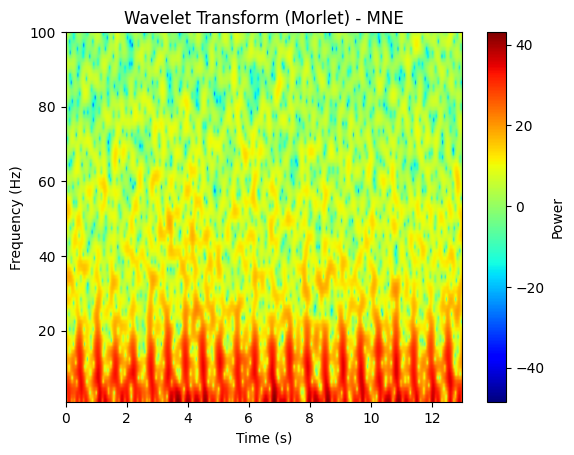

In [ ]:
#morlet with matplotlib

#Morlet wavelet

import numpy as np
import matplotlib.pyplot as plt
import mne
import DataHandling as DH
import Preprocessing as pre
import dearpygui.dearpygui as dpg


dpg.create_context()

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-11-11\\Report_Json_Session_Report_20241125T163059.json"
Data = DH.getData(file_path)
a = np.array(DH.getSignals(Data, 'Streaming')[-1]['Y'])

#Morlet wavelet

sfreq = 250
signal = a[np.newaxis, np.newaxis, :]

# Define parameters for the Morlet wavelet transform
freqs = np.arange(1, 100, 1)  # Frequencies from 1Hz to 50Hz
times = np.arange(0, len(a)/sfreq, 1)

n_cycles = freqs / 2  # Number of cycles per frequency

print(n_cycles)


tfr = mne.time_frequency.tfr_array_morlet(signal, sfreq=sfreq, freqs=freqs, n_cycles=n_cycles, output='power')

#tfr = (tfr * 100) / np.max(tfr)
tfr = 10 * np.log10(tfr) + 1e-6

# tfr = np.flipud(tfr[0, 0, :, :])

tfr = tfr[0, 0, :, ::2]

'''sfreq = 250  # Sampling frequency in Hz
times = np.linspace(0, 1, sfreq, endpoint=False)
signal = np.sin(2 * np.pi * 7 * times) + np.sin(2 * np.pi * 13 * times)

# Reshape for MNE format: (n_epochs, n_channels, n_times)
signal = signal[np.newaxis, np.newaxis, :]

# Compute Morlet wavelet transform
freqs = np.arange(1, 50, 1)  # 1Hz to 50Hz
n_cycles = freqs / 2  # Number of cycles per frequency
'''

'''sfreq = 250
signal = a[np.newaxis, np.newaxis, :]

# Define parameters for the Morlet wavelet transform
freqs = np.arange(1, 100, 1)  # Frequencies from 1Hz to 50Hz
n_cycles = freqs / 2  # Number of cycles per frequency
 ''' 




# Plot the Time-Frequency representation (scalogram)
plt.imshow(tfr, aspect='auto', extent=[0, times[-1], 1, 100], cmap='jet', origin='lower')
plt.colorbar(label='Power')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.title('Wavelet Transform (Morlet) - MNE')
plt.show()


In [ ]:
''' For feature extraction - get all scipy functions'''

import scipy.signal as ss
import Preprocessing as pre
import dearpygui.dearpygui as dpg
import DataHandling as DH
import numpy as np



#Spectral analysis
spectral_analysis_functions = ['periodogram','welch','coherence','spectrogram','stft'] 

#phase modulation, coherence (phase amplitude coupling) --> se tiver mais que 1 canal

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
stream = DH.getSignals(Data, 'Streaming')[0]


# Dictionary to store user inputs
parameter_values = {}
input_fields = {}  # Store input field IDs


dpg.create_context()

with dpg.window(label="IIR Filter Designer", width=600, height=500):
    dpg.add_text("Select a filter function:")
    param_container = dpg.add_child_window(width=-1, height=300)  # Space to add inputs dynamically

    def create_input_fields(sender, app_data):
        """Dynamically create input fields for selected function."""
        global parameter_values, input_fields
        
        dpg.delete_item(param_container, children_only=True)  # Clear previous inputs
        params = pre.get_required_params(app_data)
        
        if not params:
            dpg.add_text("No parameters found", parent=param_container)
            return
        dpg.add_text("Required parameters: ", parent=param_container)
        parameter_values.clear()  # Reset parameter storage
        input_fields.clear()  # Reset input field storage

        for param, default in params.items():
            input_id = dpg.add_input_text(
                label=param, 
                default_value=str(default) if default is not None else "",
                parent=param_container
            )
            input_fields[param] = input_id  # Store input field reference

        # Add save button
        dpg.add_button(label="Save Parameters", callback=save_parameters, parent=param_container, user_data = app_data)

    def save_parameters(sender, app_data, user_data):
        """Saves input values to the dictionary and prints them."""
        global parameter_values
        parameter_values.clear()  # Reset before saving

        for param, input_id in input_fields.items():
            value = dpg.get_value(input_id)
            parameter_values[param] = value
            print(type(value))

        print("Saved Parameters:", parameter_values)
        dpg.add_button(label="Plot filtered signal", callback=apply_filt, parent=param_container, user_data=user_data)

    def apply_filt(sender, app_data, user_data):
        func = user_data

        x = stream['X']
        y = stream['Y']

        parameter_values['x'] = y
        
        # Assuming call_function takes the filter function and the user-provided parameters
        signal = pre.call_function(func, parameter_values)
        if signal:
            plot_filtered_signal(x, y, signal)
        else: print(signal)

    def plot_filtered_signal(x, y, filtered):
        with dpg.plot(label=f"Signals", height=400, width=600, parent =param_container ):
            dpg.add_plot_legend()
            dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)", tag="x_axis")
            dpg.add_plot_axis(dpg.mvYAxis, label="LFP amp (microV)", tag="y_axis")
            dpg.add_line_series(x, y, label="Raw", parent="y_axis")
        with dpg.plot(label=f"Spectral Analysis", height=400, width=600, parent =param_container ):
            dpg.add_plot_legend()
            dpg.add_plot_axis(dpg.mvXAxis, label="Frequency (Hz)", tag="xx")
            dpg.add_plot_axis(dpg.mvYAxis, label="LFP Power (dB)", tag="yy")
            mask = filtered[0] <= 100
            freqs = filtered[0][mask]
            psd = filtered[1][mask]
            dpg.add_line_series(np.ascontiguousarray(freqs),np.ascontiguousarray(psd), label=f"Filtered", parent="yy")

            
    # Dropdown list for filters
    dpg.add_listbox(
        items=spectral_analysis_functions, 
        label="Filters", 
        callback=create_input_fields
    )

dpg.create_viewport(title='Temporario', width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()

In [ ]:
params = pre.get_required_params('periodogram')
fs = 250
arg = {}
for param, default in params.items():
    match param:
        case 'x': arg[param] =stream['Y']
        case 'fs': arg[param] = fs
        case 'window': arg[param] = 'hann'
        #case 'return_onesided': arg[param] = False
        case _:
            if default:
                print(f"{param}: {default}")
                arg[param] = default
            else:
                pass
            '''
                value = input(f"{param}: ")
                arg[param] = value'''

plt.figure()   

psd, freqs  = ft.psd_fft(stream['Y'])
plt.semilogy(freqs,psd,label="PSD_FFT")

#for i in range(670,672):
arg['nfft'] = 600
f,p = pre.call_function('periodogram', arg)
plt.semilogy(f,p, label = f"Periodogram - nfft = {arg['nfft']}")

medtronic = ft.MedtronicPSD(stream['Y'])
plt.semilogy(medtronic['Frequency'],medtronic['Power'], label = f"Medtronic")

#welch
fw, pw = ss.welch(stream['Y'],fs=fs,window='hann',nperseg=256,scaling='density')
plt.semilogy(fw,pw, label = f"Welch")
  

plt.xlim(0,100)
plt.legend()
plt.ylabel('Log Power (dB)')

plt.show()

In [ ]:
# calcular standard deviations

import DataHandling as DH
import Features as ft


file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
streams = DH.getSignals(Data, 'Streaming')
print('number of stream:', len(streams))

powers = []
for i, stream in enumerate(streams):
    print('Stream: ',i)
    medtronic = ft.MedtronicPSD(stream['Y'])
    powers.append(medtronic)
    features = ft.mean_power_all_bands(medtronic)

    bands = {
            'Delta': [0,4],
            'Theta': [4,8],
            'Alpha': [8,12],
            'Beta': [12,30],
            'Gamma': [30,100]
        }
        
    medias = [ft.mean_power_band(medtronic, band) for _, band in bands.items()]
    desvios = [ft.std_dev_band(medtronic,band) for _, band in bands.items()]

    for m,d, band in zip(medias,desvios, bands):
        print(f"{band}: Mean = {m} | Std = {d}")



desvios_all = ft.std_dev_streams(powers)
for name, list in desvios_all.items():
    print(name, ': ', list, '\n--------------------------\n')



In [ ]:
#calcular picos por bandas

import DataHandling as DH
import Features as ft
import dearpygui.dearpygui as dpg


file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
streams = DH.getSignals(Data, 'Streaming')
print('number of stream:', len(streams))

dpg.create_context()

with dpg.window(label="main", width=600, height=500):
    powers = []
    with dpg.plot():
        dpg.add_plot_legend()
        dpg.add_plot_axis(dpg.mvXAxis, label="Frequency (Hz)", tag="x_axis")
        dpg.add_plot_axis(dpg.mvYAxis, label="PSD", tag="y_axis")
        for i, stream in enumerate(streams):
            print('Stream: ',i)
            medtronic = ft.MedtronicPSD(stream['Y'])
            dpg.add_line_series(medtronic['Frequency'], medtronic['Power'], label=f"Stream {i}", parent="y_axis")
            powers.append(medtronic)
            features = ft.mean_power_all_bands(medtronic)

            bands = {
                    'Delta': [0,4],
                    'Theta': [4,8],
                    'Alpha': [8,12],
                    'Beta': [12,30],
                    'Gamma': [30,100]
                }
                
            medias = [ft.mean_power_band(medtronic, band) for _, band in bands.items()]
            desvios = [ft.std_dev_band(medtronic,band) for _, band in bands.items()]
            picos = ft.peak_per_band(medtronic)
            x, y = [], []
            for band in bands.keys():
                x.append(picos[band][0])
                y.append(picos[band][1])
            dpg.add_scatter_series(x,y, label=f"Stream {i} - peak", parent="y_axis")


            for m,d, band, peaks in zip(medias,desvios, bands, picos):
                print(f"{band}: Mean = {m} | Std = {d} | Peak: {picos[peaks]}")

    
dpg.create_viewport(title='Temporario', width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()






In [ ]:
#AUC


import Features as ft
import dearpygui.dearpygui as dpg
import DataHandling as DH
import numpy as np
import Preprocessing as pre
from scipy.signal import square

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
stream = DH.getSignals(Data, 'Streaming')[0]

#t, signal = ft.wave(frequency=20, sampling_rate=250, duration=10, amplitude=0.2)

signal = np.array(stream['Y'])


medtronic = ft.MedtronicPSD(signal)

bands = {
            'Delta': [0,4],
            'Theta': [4,8],
            'Alpha': [8,12],
            'Beta': [12,30],
            'Gamma': [30,100]
        }

dpg.create_context()

with dpg.window(label="main", width=-1, height=-1):
    with dpg.plot( width=-1, height=-1, tag = 'plot'):
        dpg.add_plot_legend()
        dpg.add_plot_axis(dpg.mvXAxis, label="Time", tag="x_axis")
        dpg.add_plot_axis(dpg.mvYAxis, label="AUC", tag="y_axis")
        dpg.add_shade_series(medtronic['Frequency'], medtronic['Power'], label='Raw', parent="y_axis")
        i=0

        for function in ['trapezoid','simpson']: #'simpson','trapezoid','cumulative_simpson','cumulative_trapezoid'
            i+=1

            params = pre.get_required_params(function, module='si')
            parameters = {}
            for name, param in params.items():
                if param == None:
                    value = input(f"{name}: ")
                else:
                    value = param
                parameters[name] =value
            for _, band in bands.items():
                a, b = band
                freq_array = medtronic['Frequency']
                mask = (freq_array >= a) & (freq_array <= b)
                
                parameters['y'] = medtronic['Power'][mask]
                f = freq_array[mask]

                if len(f) == 0:
                    print(f"Warning: No data in band {band}")
                    continue

                auc = pre.call_function(function, param_dict=parameters, module='si')
                print(auc)
        



    
dpg.create_viewport(title='Temporario', width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()

In [ ]:
#Multitaper scipy  -beginning

import numpy as np                                                                        
from scipy.signal import windows, stft  
import scipy.signal as ss                                                  
from numpy.random import randn    
import matplotlib.pyplot as plt    
import DataHandling as DH
                                                                                          
'''nSamples = 1000                                                                           
win_size = nSamples // 4                                                                  
# create a slepian sequence of 6 orthogonal tapers                                        
slepians = windows.dpss(win_size, NW=2, Kmax=6)                                           
signal = randn(nSamples)                                                                  
                                                                                          
nSamples = 1000
t = np.linspace(0, 1000, nSamples, endpoint=False)
sig = ss.square(2 * np.pi * 5 * t)

'''

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
stream = DH.getSignals(Data, 'Streaming')[0]
                                                                                          
nSamples = len(stream['X'])                                                                           
win_size = nSamples // 4                                                                  
# create a slepian sequence of 6 orthogonal tapers                                        
slepians = windows.dpss(win_size, NW=2, Kmax=6)                                           
                               
sig = stream['Y']

print(stream['Channel'])

for sym in (True, False):
    for win_size in (nSamples, nSamples // 4):
        nw = 3
        slepians = ss.windows.dpss(
            win_size, NW=nw, Kmax=2*nw-1, sym=sym)
        #kmax = 2*NW-1
        power_combined = []
        print(f"win_size: {win_size}, sym: {sym}")
        for order, taper in enumerate(slepians):
            freq_welch, pxx = ss.welch(sig, window=taper, fs=250, nperseg=win_size)
            power_combined.append(pxx)
            # the mean power over all windows
            power_sum = np.abs(pxx).mean()
            print(f'order {order}: {power_sum:e}')

        power_combined = np.mean(power_combined, axis=-2)
        freq_periodogram, psd = ss.periodogram(sig,fs=250)

        fig = plt.figure()

        mask1 = freq_periodogram <= 100
        mask2 = freq_welch <= 100

        plt.plot(freq_periodogram[mask1], psd[mask1], label="periodogram")
        plt.plot(freq_welch[mask2], power_combined[mask2], label="welch_dpss")
        plt.title(f"win_size: {win_size}, sym: {sym}")
        plt.legend()

plt.show()

In [ ]:
#Multitaper scipy e normalização e funções interface + comparação multitaper MNE


import matplotlib.pyplot as plt    
import DataHandling as DH
import Preprocessing as pre
import numpy as np
                                                                                          
'''nSamples = 1000                                                                           
win_size = nSamples // 4                                                                  
# create a slepian sequence of 6 orthogonal tapers                                        
slepians = windows.dpss(win_size, NW=2, Kmax=6)                                           
signal = randn(nSamples)                                                                  
                                                                                          
nSamples = 1000
t = np.linspace(0, 1000, nSamples, endpoint=False)
sig = ss.square(2 * np.pi * 5 * t)

'''

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
stream = DH.getSignals(Data, 'Streaming')[0]

def fill_params(func, replace, module):


    params = pre.get_required_params(func, module)

    parameters = {}
    for name, param in params.items():            
        if param == None:
            value = ""
        
        else:
            value = param

        parameters[name] =value

    if func == 'dpss':
        parameters['NW'] = 3
        parameters['Kmax'] = int(parameters['NW'])*2 -1
        parameters['M'] = len(stream['X'])
        

    if replace != {}:
        for name, value in replace.items():
            parameters[name] = value
    
    return parameters

parameters = fill_params('dpss',{}, module='ssw')


windows = pre.call_function('dpss',param_dict=parameters,module='ssw')

power_combined = []
for order, taper in enumerate(windows):
    
    replace = {
        'x': stream['Y'],
        'fs': 250, 
        'window': taper,
        'nperseg': len(stream['Y'])
    }
    welch_params = fill_params('welch',replace, module='ss')

    freq, psd = pre.call_function('welch',param_dict=welch_params,module='ss')
    power_combined.append(psd)
    power_sum = np.abs(psd).mean()


power_combined = np.mean(power_combined, axis=-2)
params = {
    'x': stream['Y'],
    'fs': 250
}

rep = {
    'x': np.array(stream['Y']),
    'sfreq': 250
}

multi_params = fill_params('psd_array_multitaper',replace=rep, module='mtf')

multitaper, freqs = pre.call_function('psd_array_multitaper', multi_params, module='mtf')


plt.figure()

mask1 = freqs <= 100
mask2 = freq <= 100

multitaper = np.array([m*100/np.max(multitaper[mask1]) for m in multitaper])
power_combined = np.array([m*100/np.max(power_combined[mask2]) for m in power_combined])

plt.plot(freqs[mask1], multitaper[mask1], label = 'multitaper mne')
plt.plot(freq[mask2], power_combined[mask2], label="welch_dpss")

plt.legend()
plt.show()

## Percept feature extraction

In [ ]:
from scipy import signal

def plot_pwelch(data, fs, *args):
    """
    Plot Power Spectral Density (PSD) using Welch's method for each channel.

    Parameters:
    data : ndarray
        2D array where each column corresponds to a channel's data.
    params : dict
        Dictionary containing the parameters with keys:
        - 'Fs': Sampling frequency (Hz).
        - 'nChannels': Number of channels.
        - 'channel_names': List of channel names.
        - 'channel_map': 2D array specifying subplot arrangement.
    args : tuple
        Optional arguments. Pass 'log' to convert PSD to dB.

    Returns:
    Pxx : ndarray
        Power spectral density of the data.
    F : ndarray
        Frequency array corresponding to the PSD.
    """
    # Compute Welch's method with 0.1 Hz frequency resolution
    window = int(round(5 * fs))  # Default window size
    noverlap = int(round(window * 0.5))    # Default overlap
    
    fmin = 1               # Hz
    fmax = fs / 2  # Nyquist frequency

    Pxx = []

    f, pxx = ss.welch(data, fs=fs, window='hann', nperseg=window, noverlap=noverlap, scaling='density')
    mask = (f >= fmin) & (f <= fmax)
    Pxx.append(pxx[mask])
    
    Pxx = np.array(Pxx).T  # Transpose to match channel-wise structure
    
    # Convert PSD to dB if 'log' is provided in args
    if len(args) > 0 and args[0].lower() == 'log':
        Pxx = 10 * np.log10(Pxx)
        ylabel = 'PSD (dB/Hz)'
    else:
        ylabel = 'PSD (µV²/Hz)'

    # Plotting

    # Plot PSD
    plt.figure()
    plt.plot(f, pxx, label='PSD Welch', linewidth=1)
    
    
    plt.ylabel(ylabel)
    plt.xlabel('Frequency (Hz)')
    plt.grid(True)
    plt.xlim([fmin, fmax])
    plt.tight_layout()
    plt.show()

    return Pxx, f


def plot_spectrogram(data, channel_params, *args):
    """
    Compute and plot the spectrogram for each channel.

    Parameters:
    data : ndarray
        2D array where each column corresponds to a channel's data.
    channel_params : dict
        Dictionary containing channel parameters with keys:
        - 'Fs': Sampling frequency (Hz).
        - 'nChannels': Number of channels.
        - 'channel_names': List of channel names.
        - 'channel_map': 2D array specifying subplot arrangement.
        - 'time': Array of time values.
    args : tuple
        Optional arguments. Pass 'normalize' to normalize power values.

    Returns:
    spectro_fig : matplotlib.figure.Figure
        The figure object containing the spectrogram plots.
    """
    normalize_power = 'normalize' in args

    # Default spectrogram parameters
    window = int(round(0.5 * 250))  # 0.5 second
    noverlap = int(round(window / 2))
    fmin = 1  # Hz
    fmax = 125  # Hz

    # Initialize figure
    spectro_fig, axes = plt.subplots(
        *channel_params['channel_map'].shape, figsize=(12, 8), squeeze=False
    )
    axes_flat = axes.flatten()

    for ch_id in range(len(data)):
        channel_pos = np.argwhere(channel_params['channel_map'] == ch_id + 1).flatten()
        ax = axes[channel_pos[0], channel_pos[1]]

        # Compute spectrogram
        f, t, Sxx = signal.spectrogram(
            data[:, ch_id],
            fs=channel_params['Fs'],
            window='hann',
            nperseg=window,
            noverlap=noverlap,
            scaling='density',
            mode='psd'
        )

        # Filter frequencies
        freq_mask = (f >= fmin) & (f <= fmax)
        f = f[freq_mask]
        Sxx = Sxx[freq_mask, :]

        # Normalize power if requested
        if normalize_power:
            power_to_plot = 10 * np.log10(Sxx / np.mean(Sxx, axis=1, keepdims=True))
        else:
            power_to_plot = 10 * np.log10(Sxx)

        # Plot spectrogram
        img = ax.imshow(
            power_to_plot,
            aspect='auto',
            extent=[t[0], t[-1], f[0], f[-1]],
            origin='lower',
            cmap='viridis'
        )

        ax.set_title(channel_params['channel_names'][ch_id])
        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Frequency (Hz)')
        ax.grid(False)

        # Add colorbar
        cbar = plt.colorbar(img, ax=ax)
        cbar.set_label('Power/Frequency (dB/Hz)')

    # Link axes
    for ax in axes_flat:
        ax.label_outer()
    plt.tight_layout()

    return spectro_fig

# FILTROS

In [ ]:
# Hilbert Transform
import scipy.signal as ss
import numpy as np

filtered = ss.hilbert(y[:250])
fs = 250
amplitude_envelope = np.abs(filtered)
instantaneous_phase = np.unwrap(np.angle(filtered))
instantaneous_frequency = np.diff(instantaneous_phase) / (2.0*np.pi) * fs

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
'''
ax1.plot(x,y,label = 'Raw')
ax2.plot(x,filtered,label = 'Median Filter')

ax1.legend()
ax2.legend()'''

ax1.plot(x[:250],y[:250],label = 'Raw')
ax1.plot(x[:250],amplitude_envelope,label = 'Hilbert Envelope', linestyle = '--')
ax2.plot(x[1:250],instantaneous_frequency,label = 'Hilbert Instantaneoys Phase', linestyle = '--')

ax1.legend()
ax2.legend()

plt.legend()
plt.show()

In [ ]:
# Decimate, by 10

filtered = ss.decimate([x,y],10)
fs = 250



fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))


ax1.plot(x,y,label = 'Raw')
ax2.plot(filtered[0],filtered[1],label = 'Decimate')

ax1.legend()
ax2.legend()

plt.legend()
plt.show()

In [ ]:
#Cardiac Component Remover - BRAVO

from scipy import signal, optimize
import numpy as np
import DataHandling as DH
import matplotlib.pyplot as plt

def waveletTimeFrequency(data, freq, ma=1, w=6, fs=100):
    widths = w * fs / (2 * freq * np.pi)
    cwtm = signal.cwt(data, signal.morlet2, widths, w=w)
    power = np.abs(cwtm)
    if ma > 1:
        for i in range(len(data)):
            if i < ma:
                power[:,i] = np.mean(power[:,:i+ma],axis=1)
            elif i+ma >= len(data):
                power[:,i] = np.mean(power[:,i-ma:],axis=1)
            else:
                power[:,i] = np.mean(power[:,i-ma:i+ma],axis=1)
    return dict({"Time": np.array(range(len(data)))/fs,"Frequency": freq, "Power": power, "logPower": 10*np.log10(power)})

def defaultSpectrogram(data, window=2.0, overlap=1.0, frequency_resolution=0.5, fs=100):
    configuration = {"Window": window, "Overlap": overlap}
    window = int(window * fs)
    overlap = int(overlap * fs)
    NFFT = int(fs / frequency_resolution)
    frequency, time, spectrum = signal.spectrogram(data, window="hamming", nperseg=window, noverlap=overlap, nfft=NFFT, fs=fs)
    return dict({"Time": time, "Frequency": frequency, "Power": np.abs(spectrum), "logPower": 10*np.log10(np.abs(spectrum)), "Config": configuration})

def removeCardiacComponent(raw, filterMethod="Fixed Peak Find"):
    stream = raw['Y']
    fs = 250
    #Filtrar bandpass butter
    [b,a] = signal.butter(5, np.array([1,100])*2/fs, 'bp', output='ba')
    filtered = signal.filtfilt(b, a, stream)
    buttered = filtered.copy()

    #filterMethod = "Kurtosis"
    PredictedSignal = signal.wiener(filtered, mysize=125)
    filtered -= PredictedSignal

    if filterMethod == "Fixed Peak Find":
        # Cardiac Filter
        posPeaks,_ = signal.find_peaks(filtered, prominence=[10,200], distance=fs*0.5)
        PosCardiacVariability = np.std(np.diff(posPeaks))
        negPeaks,_ = signal.find_peaks(-filtered, prominence=[10,200], distance=fs*0.5)
        NegCardiacVariability = np.std(np.diff(negPeaks))

        if PosCardiacVariability < NegCardiacVariability:
            peaks = posPeaks
        else:
            peaks = negPeaks
        CardiacRate = int(np.mean(np.diff(peaks)))

        PrePeak = int(CardiacRate*0.25)
        PostPeak = int(CardiacRate*0.65)
        EKGMatrix = np.zeros((len(peaks)-2,PrePeak+PostPeak))
        for j in range(1,len(peaks)-1):
            if peaks[j]+PostPeak < len(filtered) and peaks[j]-PrePeak > 0:
                EKGMatrix[j-1,:] = filtered[peaks[j]-PrePeak:peaks[j]+PostPeak]

        EKGTemplate = np.mean(EKGMatrix,axis=0)
        EKGTemplate = EKGTemplate / (np.max(EKGTemplate)-np.min(EKGTemplate))

        def EKGTemplateFunc(xdata, amplitude, offset):
            return EKGTemplate * amplitude + offset

        for j in range(len(peaks)):
            if peaks[j]-PrePeak < 0:
                pass
            elif peaks[j]+PostPeak >= len(filtered) :
                pass
            else:
                sliceSelection = np.arange(peaks[j]-PrePeak,peaks[j]+PostPeak)
                params, covmat = optimize.curve_fit(EKGTemplateFunc, sliceSelection, filtered[sliceSelection])
                filtered[sliceSelection] = filtered[sliceSelection] - EKGTemplateFunc(sliceSelection, *params)
                ecg = EKGTemplateFunc(sliceSelection, *params)

        #wavelet = waveletTimeFrequency(filtered, freq=np.arange(0.5,100.5,0.5), ma=int(fs/2), fs=fs)
        #sfft = defaultSpectrogram(stream, window=1.0, overlap=0.5, frequency_resolution=0.5, fs=fs)

        return filtered, ecg, buttered, peaks
    
file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
stream = DH.getSignals(Data, 'Streaming')[0]

filtered, ecg, buttered, peaks = removeCardiacComponent(stream)

threshold = []
for p in peaks:
    threshold.append(stream['Y'][p])
#threshold = [np.abs(v) for v in threshold]

line = np.min(threshold)

plt.figure()

#plt.plot(stream['X'],stream['Y'],label='Raw')

plt.plot(stream['X'],buttered,label='Butter Filter')
plt.plot(stream['X'],filtered,label='No Cardiac Component', linestyle = '--')
plt.plot(np.arange(0,len(ecg)),ecg, label = 'ECG')
plt.hlines(y = [line, - line], xmin = 0, xmax = len(stream['X'])/250, label = 'Threshold', color = 'red', linestyle = '--')

plt.legend()
plt.show()

print('end')

## Spectrogram DPG

In [ ]:
import scipy.signal as ss
import Preprocessing as pre
import dearpygui.dearpygui as dpg
import DataHandling as DH
import numpy as np

''' For feature extraction - get all scipy functions'''

#Spectral analysis
spectral_analysis_functions = ['periodogram','welch','spectrogram',] 

#phase modulation, coherence (phase amplitude coupling) --> se tiver mais que 1 canal

file_path = "C:\\Users\\OCD\\Desktop\\DATA\\RN\\2024-10-14\\Report_Json_Session_Report_20241125T162143.json"
Data = DH.getData(file_path)
stream = DH.getSignals(Data, 'Streaming')[-1]


# Dictionary to store user inputs
parameter_values = {}
input_fields = {}  # Store input field IDs


dpg.create_context()

with dpg.window(label="IIR Filter Designer", width=600, height=500):
    dpg.add_text("Select a filter function:")
    param_container = dpg.add_child_window(width=-1, height=300)  # Space to add inputs dynamically

    def create_input_fields(sender, app_data):
        """Dynamically create input fields for selected function."""
        global parameter_values, input_fields
        
        dpg.delete_item(param_container, children_only=True)  # Clear previous inputs
        params = pre.get_required_params(app_data)
        
        if not params:
            dpg.add_text("No parameters found", parent=param_container)
            return
        dpg.add_text("Required parameters: ", parent=param_container)
        parameter_values.clear()  # Reset parameter storage
        input_fields.clear()  # Reset input field storage

        for param, default in params.items():
            input_id = dpg.add_input_text(
                label=param, 
                default_value=str(default) if default is not None else "",
                parent=param_container
            )
            input_fields[param] = input_id  # Store input field reference

        # Add save button
        dpg.add_button(label="Save Parameters", callback=save_parameters, parent=param_container, user_data = app_data)

    def save_parameters(sender, app_data, user_data):
        """Saves input values to the dictionary and prints them."""
        global parameter_values
        parameter_values.clear()  # Reset before saving

        for param, input_id in input_fields.items():
            value = dpg.get_value(input_id)
            parameter_values[param] = value

        print("Saved Parameters:", parameter_values)
        dpg.add_button(label="Plot filtered signal", callback=apply_filt, parent=param_container, user_data=user_data)

    def apply_filt(sender, app_data, user_data):
        func = user_data

        x = stream['X']
        y = stream['Y']

        parameter_values['x'] = np.array(y)
        
        # Assuming call_function takes the filter function and the user-provided parameters
        signal = pre.call_function(func, parameter_values)
        if signal:
            if func == 'spectrogram': plot_spectrogram(signal)
            else:
                plot_filtered_signal(x, y, signal)
        
    def plot_filtered_signal(x, y, filtered):
        with dpg.plot(label=f"Signals", height=400, width=600, parent =param_container ):
            dpg.add_plot_legend()
            dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)", tag="x_axis")
            dpg.add_plot_axis(dpg.mvYAxis, label="LFP amp (microV)", tag="y_axis")
            dpg.add_line_series(x, y, label="Raw", parent="y_axis")
        with dpg.plot(label=f"Spectral Analysis", height=400, width=600, parent =param_container ):
            dpg.add_plot_legend()
            dpg.add_plot_axis(dpg.mvXAxis, label="Frequency (Hz)", tag="xx")
            dpg.add_plot_axis(dpg.mvYAxis, label="LFP Power (dB)", tag="yy")
            mask = filtered[0] <= 100
            freqs = filtered[0][mask]
            psd = filtered[1][mask]
            dpg.add_line_series(np.ascontiguousarray(freqs),np.ascontiguousarray(psd), label=f"Filtered", parent="yy")

    def plot_spectrogram(signal):
        frequencies, times, Sxx = signal
        Sxx_log = 10 * np.log10(Sxx + 1e-10)  # Convert to dB scale
        Sxx_log = np.flipud(Sxx_log)

        with dpg.group(horizontal=True,parent =param_container, tag = 'spec'):
            # Spectrogram (Heatmap) with Colormap
            with dpg.plot(label="Spectrogram", width=600, height=300, tag = 'sss',parent ='spec'):
                dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)", tag="x_axis_spec")
                dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)", tag="y_axis_spec")

                label_pairs = ()
                for i in np.arange(0, Sxx_log.shape[0], 0.1):
                    label_pairs += ((f"{i*len(times):.0f}", i),)
                dpg.set_axis_ticks('x_axis_spec', label_pairs)

                freq_pairs = ()
                for i in np.arange(0, Sxx_log.shape[1],0.1):
                    freq_pairs += ((f"{i*max(frequencies):.0f}", i),)
                dpg.set_axis_ticks('y_axis_spec', freq_pairs)

                dpg.add_heat_series(Sxx_log.flatten(), rows=Sxx_log.shape[0], cols=Sxx_log.shape[1],
                                            scale_min=Sxx_log.min(), scale_max=Sxx_log.max(), 
                                            parent="y_axis_spec", format="")
                
            dpg.add_colormap_scale(tag="colormap_scale", label="Density", colormap=dpg.mvPlotColormap_Hot,
                                            min_scale = np.min(Sxx_log), max_scale=np.max(Sxx_log), height=300)
            dpg.bind_colormap("sss", dpg.mvPlotColormap_Hot)
            dpg.set_axis_limits_auto('x_axis_spec')
            

    # Dropdown list for filters
    dpg.add_listbox(
        items=spectral_analysis_functions, 
        label="Filters", 
        callback=create_input_fields
    )

dpg.create_viewport(title='Temporario', width=800, height=600)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()

In [ ]:
def plot_spectrogram(signal, tags, func):
        frequencies, times, Sxx = signal
        Sxx_log = 10 * np.log10(Sxx + 1e-10)  # Convert to dB scale
        Sxx_log = np.flipud(Sxx_log)

        num_plots = len(tags)
        num_cols = 2
        num_rows = (num_plots + 1) // num_cols  # Determine the required rows for the grid

        with dpg.group(horizontal=True, parent=f"{tab_tag}_{func}", tag=f"{tab_tag}_spec"):
            # Create a subplot grid with dynamic rows and fixed 2 columns
            with dpg.subplots(rows=num_rows, columns=num_cols, label="Spectrograms", width=800, height=400*num_rows, tag=f"{tab_tag}_subplots"):
                
                for tag in tags:
                    stream = getSignalbyIdx(window_id, tab_tag, tag)
                    idx = extract_idx_from_series_tag(tag)
                    y = stream['Y']
                    channel = stream['Channel']
                    parameter_values['x'] = np.array(y)
                    signal = pre.call_function(func, parameter_values)
                    app_state['windows'][window_id]['Data'][tab_tag]['Signals'][idx][func] = signal

                    frequencies, times, Sxx = signal
                    Sxx_log = 10 * np.log10(Sxx + 1e-10)  # Convert to dB scale
                    Sxx_log = np.flipud(Sxx_log)

                    # Create a new subplot for each heat series
                    
                    with dpg.plot(label=f"Spectrogram - {channel}", width=-1, height=-1, tag = f"{tab_tag}_{func}_{channel}"):
                        x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                        y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)")


                        label_pairs = ()
                        for i in np.arange(0, Sxx_log.shape[0], 0.1):
                            label_pairs += ((f"{i*len(times):.0f}", i),)
                        dpg.set_axis_ticks(x_axis, label_pairs)

                        freq_pairs = ()
                        for i in np.arange(0, Sxx_log.shape[1],0.1):
                            freq_pairs += ((f"{i*max(frequencies):.0f}", i),)
                        dpg.set_axis_ticks(y_axis, freq_pairs)


                        dpg.add_heat_series(Sxx_log.flatten(), rows=Sxx_log.shape[0], cols=Sxx_log.shape[1],
                                                scale_min=Sxx_log.min(), scale_max=Sxx_log.max(), 
                                                parent=y_axis, format="")
                                                
                        
                        dpg.bind_colormap(f"{tab_tag}_{func}_{channel}", dpg.mvPlotColormap_Jet)
                        
            dpg.add_colormap_scale(tag=f"{tab_tag}_{channel}_colormap_scale", label="Density", colormap=dpg.mvPlotColormap_Jet,
                                                min_scale = np.min(Sxx_log), max_scale=np.max(Sxx_log), height=300, parent=y_axis)

     
    create_input_fields(sender,app_data)

In [ ]:
def plot_spectrogram_ind(tags, tab_label, func, tab_tag, parameter_values, mode = None):
    #tab_label = f"{tab_tag}_{func}"
    window_id = extract_window_id(tab_tag)
    if 'Files' in app_state['windows'][window_id]:
        if 'Events' in app_state['windows'][window_id]['Files'][-1]['Data'][tab_tag].keys():
            mode = 'segment'
        else: mode = None
    else: mode = None
    num_plots = len(tags)
    num_cols = 2
    num_rows = (num_plots + 1) // num_cols  # Determine the required rows for the grid

    global_min = float("inf")
    global_max = float("-inf")

    Merge = []
    per_file = {}
    for tag in tags:
        stream = getSignalbyIdx(window_id,tab_tag,tag,mode=mode)
        file = extract_file_from_series_tag(tag)
        y = stream['Y']
        parameter_values['x'] = np.array(y)
        signal = pre.call_function(func, parameter_values)
        if file != None: per_file[file] = []

        frequencies, times, Sxx = signal
        Sxx_log = 10 * np.log10(Sxx + 1e-10)  # Convert to dB scale
        Sxx_log = np.flipud(Sxx_log)

        global_min = min(global_min, Sxx_log.min())
        global_max = max(global_max, Sxx_log.max())     

    with dpg.group(horizontal=True, parent=f"{tab_label}", tag=f"{tab_label}_plot_group"):

        dpg.add_colormap_scale(tag=f"{tab_label}_colormap_scale", label="Density", colormap=dpg.mvPlotColormap_Jet,
                                            min_scale = global_min, max_scale=global_max, height=400*num_rows)
        
        with dpg.subplots(rows=num_rows, columns=num_cols, label="Spectrograms", width=800, height=400*num_rows, tag=f"{tab_label}_subplots"):
            for i,tag in enumerate(tags):
                stream = getSignalbyIdx(window_id, tab_tag, tag, mode=mode)
                file = extract_file_from_series_tag(tag)
                y = stream['Y']
                channel = stream['Channel']
                date = stream['Date']
                parameter_values['x'] = np.array(y)
                signal = pre.call_function(func, parameter_values)
                per_file[file].append(signal)
                updateSignalbyIdx(signal,tab_tag,tag,func)

                Merge.append(signal)

                frequencies, times, Sxx = signal
                Sxx_log = 10 * np.log10(Sxx + 1e-10)  # Convert to dB scale
                Sxx_log = np.flipud(Sxx_log)

                # Create a new subplot for each heat series
                if mode:
                    plot_label = f"{channel} - {stream['Type']} {i} - {date}"
                    plot_tag = f"{tab_label}_{channel}_{stream['Type']}_{i}"
                else:
                    plot_label = f"{channel} | {date}"
                    plot_tag = f"{tab_label}_{channel}_{date}"
                
                with dpg.plot(label=plot_label, width=-1, height=-1, tag = plot_tag):
                    x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                    y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)")


                    label_pairs = ()
                    #for i in np.arange(0, 1, 1/len(times)):
                    if mode:
                        emin = int(dpg.get_value(f"{tab_tag}_emin"))
                        emax = int(dpg.get_value(f"{tab_tag}_emax"))
                        for i in np.arange(0, Sxx_log.shape[1], 0.1):
                            label_pairs += ((f"{(i*(emin+emax)-emin):.1f}", i),)
                    else:
                        for i in np.arange(0, Sxx_log.shape[0], 0.1):
                            label_pairs += ((f"{i*len(times):.1f}", i),)
                        
                    dpg.set_axis_ticks(x_axis, label_pairs)

                    freq_pairs = ()
                    for i in np.arange(0, Sxx_log.shape[0],0.1):
                        freq_pairs += ((f"{i*125:.0f}", i),)
                    dpg.set_axis_ticks(y_axis, freq_pairs)


                    dpg.add_heat_series(Sxx_log.flatten(), rows=Sxx_log.shape[0], cols=Sxx_log.shape[1],
                                            scale_min=global_min, scale_max=global_max, 
                                            parent=y_axis, format="")
                                            
                    
                    dpg.bind_colormap(plot_tag, dpg.mvPlotColormap_Jet)

        def link(sender, app_data):
            dpg.configure_item(f"{tab_label}_subplots", link_all_x=app_data, link_all_y=app_data)

        def mean_spectrogram(all_Sxx, file = None):
            shapes = [s.shape for s in all_Sxx]
            if not all(shape == shapes[0] for shape in shapes):
                e = "All spectrograms must have the same time length to compute the mean."
                dpg.add_text(e, parent=f"{tab_label}_plot_group")
                raise ValueError(e)

            # Compute the mean spectrogram (linear scale)
            mean_Sxx = np.mean(np.stack(all_Sxx), axis=0)

            # Convert to dB
            mean_Sxx_log = 10 * np.log10(mean_Sxx + 1e-10)
            mean_Sxx_log = np.flipud(mean_Sxx_log)
            
            if file == None: 
                title = "Mean Spectrogram"
                subplot_tag = f"{tab_label}_mean"
            else: 
                title =f"Mean Spectrogram - File {file}"
                subplot_tag = f"{tab_label}_mean_{file}"

            with dpg.plot(label=title, width=500, height=400, tag=subplot_tag, parent=f"{tab_label}_merged"):
                x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)")

                # Optional: reuse label_pairs and freq_pairs from earlier, or recalculate
                label_pairs,freq_pairs = (), ()
                if mode:
                    emin = int(dpg.get_value(f"{tab_tag}_emin"))
                    emax = int(dpg.get_value(f"{tab_tag}_emax"))
                    for i in np.arange(0, Sxx_log.shape[0], 0.1):
                        label_pairs += ((f"{(i*(emin+emax)-emin):.1f}", i),)
                else:
                    for i in np.arange(0, Sxx_log.shape[0], 0.1):
                        label_pairs += ((f"{i*len(times):.1f}", i),)
                    
                for i in np.arange(0, Sxx_log.shape[1],0.1): freq_pairs += ((f"{i*125:.0f}", i),) 

                dpg.set_axis_ticks(x_axis, label_pairs)
                dpg.set_axis_ticks(y_axis, freq_pairs)

                dpg.add_heat_series(mean_Sxx_log.flatten(), rows=mean_Sxx_log.shape[0], cols=mean_Sxx_log.shape[1],
                                    scale_min=global_min, scale_max=global_max,
                                    parent=y_axis, format="")
                dpg.bind_colormap(subplot_tag, dpg.mvPlotColormap_Jet)
                
        def merge_spectrograms(sender,app_data,user_data):
            all_Sxx = [s[2] for s in Merge]  # s[2] is the Sxx in (frequencies, times, Sxx)
            
            if dpg.does_item_exist(f"{tab_label}_merged"):dpg.delete_item(f"{tab_label}_merged")

            with dpg.group(horizontal=True, parent=tab_label, tag = f"{tab_label}_merged"):
                mean_spectrogram(all_Sxx)

                if len(per_file.keys())>1:
                    for file, signals in per_file.items():
                        all_Sxx = [s[2] for s in signals]
                        mean_spectrogram(all_Sxx, file=file)
            
            if mode == 'segment':
                with dpg.plot(tag=f"{tab_label}_bands_merged", parent=f"{tab_label}_merged", width=-1, height=400):
                    dpg.add_plot_legend()
                    x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                    y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Power (dB)")

                    with dpg.theme() as alpha_theme:
                            with dpg.theme_component(0):
                                dpg.add_theme_style(dpg.mvPlotStyleVar_FillAlpha, 0.5, category=dpg.mvThemeCat_Plots)

                    for b,v in bands.items():
                        band_slices = []
                        for sxx in all_Sxx:
                            # sxx shape: (frequencies, time)
                            mask = (frequencies*125 >= v[0]) & (frequencies*125 < v[1])
                            if np.any(mask):
                                band_power = np.mean(sxx[mask, :],axis=0)  # mean across freqs -> shape: (time,)
                                band_power = 10 * np.log10(band_power + 1e-10)
                                band_slices.append(band_power)

                        if band_slices:
                            power = np.mean(np.stack(band_slices), axis=0)
                            # variance = np.var(np.stack(band_slices),axis=0)
                            std = np.std(np.stack(band_slices), axis=0)
                            min_std = power-std
                            max_std = power+std

                            time_array = np.linspace(-emin,emax,sxx.shape[1])
                            dpg.add_shade_series(time_array,min_std,y2=max_std,label = f"{b} Std. Deviation", tag=f"{tab_label}_{b}_std", parent=y_axis)
                            dpg.bind_item_theme(f"{tab_label}_{b}_std", alpha_theme)
                            # dpg.add_line_series(time_array,variance,label = f"{b} - variance", parent=y_axis)
                            dpg.add_line_series(time_array,power,label = f"{b} Mean", tag=f"{tab_label}_{b}_mean", parent=y_axis)
                            # dpg.add_error_series(time_array,power,std,std,label = f"{b} Std. Deviation", tag=f"{tab_label}_{b}_std", parent=y_axis)


        with dpg.group(horizontal=False):
            dpg.add_checkbox(label='Synchronize Axis', callback=link)      
            # if mode:
            dpg.add_button(label='Merge Spectrograms', callback=merge_spectrograms)


In [ ]:
#add events to mean spectrogram


def plot_spectrogram_individual(tags, tab_label, func, tab_tag, parameter_values, mode = None):
    window_id = extract_window_id(tab_tag)

    global_min = float("inf")
    global_max = float("-inf")

    all_Sxx = []
    per_rec = {}

    #initialize lists of signals per date
    for tag in tags: 
        date = getSignalbyIdx(window_id,tab_tag,tag,mode=mode)['Date']
        date = f"{date.day:02d}/{date.month:02d} - {date.hour:02d}:{date.minute:02d}"
        per_rec[date] = {}

    for tag in tags:
        stream = getSignalbyIdx(window_id,tab_tag,tag,mode=mode)
        stream_events = getEventsbyTag(tab_tag,tag)
        y = stream['Y']
        parameter_values['x'] = np.array(y)
        date = stream['Date']
        channel = stream['Channel']
        date = f"{date.day:02d}/{date.month:02d} - {date.hour:02d}:{date.minute:02d}"
        signal = pre.call_function(func, parameter_values)

        frequencies, times, Sxx = signal
        per_rec[date] = {channel: signal, 'Events': stream_events}
        Sxx_log = 10 * np.log10(Sxx + 1e-10)  # Convert to dB scale
        Sxx_log = np.flipud(Sxx_log)

        global_min = min(global_min, Sxx_log.min())
        global_max = max(global_max, Sxx_log.max())     
        all_Sxx.append(Sxx_log)
    
    num_plots = len(per_rec.keys())
    num_cols = 1
    num_rows = num_plots

    with dpg.group(horizontal=True, parent=f"{tab_label}", tag=f"{tab_label}_plot_group"):

        dpg.add_colormap_scale(tag=f"{tab_label}_colormap_scale", label="Density", colormap=dpg.mvPlotColormap_Jet,
                                            min_scale = global_min, max_scale=global_max, height=400*num_rows)
        
        def mean_spectrogram(signals, file = None):  

            if isinstance(signals,dict):  
                all_Sxx = []

                events = signals['Events']
                signals.pop('Events',None)
                all_Sxx = [sxx for _, sxx in signals.items()]
            else: 
                all_Sxx = signals
                events = None

            if file == None: 
                title = "Mean Spectrogram"
                subplot_tag = f"{tab_label}_mean"
                mean_Sxx_log = np.mean(np.stack(all_Sxx), axis=0)
            else: 
                all_Sxx = [s[2] for s in all_Sxx]
                mean_Sxx_log = np.mean(np.stack(all_Sxx), axis=0)
                title =f"Mean Spectrogram - File {file}"
                subplot_tag = f"{tab_label}_mean_{file}"
                mean_Sxx_log = 10 * np.log10(mean_Sxx_log + 1e-10)
                mean_Sxx_log = np.flipud(mean_Sxx_log)
            
            shapes = [s.shape for s in all_Sxx]
            times = all_Sxx[0][1]
            if not all(shape == shapes[0] for shape in shapes):
                e = "All spectrograms must have the same time length to compute the mean."
                dpg.add_text(e, parent=f"{tab_label}_plot_group")
                raise ValueError(e)

            with dpg.plot(label=title, width=500, height=400, tag=subplot_tag, parent=f"{tab_label}_merged"):
                x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)")

                # Optional: reuse label_pairs and freq_pairs from earlier, or recalculate
                label_pairs,freq_pairs = (), ()
                if mode:
                    emin = int(dpg.get_value(f"{tab_tag}_emin"))
                    emax = int(dpg.get_value(f"{tab_tag}_emax"))
                    for i in np.arange(0, mean_Sxx_log.shape[0], 0.1):
                        label_pairs += ((f"{(i*(emin+emax)-emin):.1f}", i),)
                else:
                    for i in np.arange(0, mean_Sxx_log.shape[0], 0.1):
                        label_pairs += ((f"{i*len(times):.1f}", i),)
                    
                for i in np.arange(0, mean_Sxx_log.shape[1],0.1): freq_pairs += ((f"{i*125:.0f}", i),) 

                dpg.set_axis_ticks(x_axis, label_pairs)
                dpg.set_axis_ticks(y_axis, freq_pairs)

                dpg.add_heat_series(mean_Sxx_log.flatten(), rows=mean_Sxx_log.shape[0], cols=mean_Sxx_log.shape[1],
                                    scale_min=global_min, scale_max=global_max,
                                    parent=y_axis, format="")
                dpg.bind_colormap(subplot_tag, dpg.mvPlotColormap_Jet)

                if events != None:
                    for event in events:
                        stamp = [event['Idx']/(len(times)*250)] #spectrogram axis is in reality from 0 to 1, and the columns are time based, not sample
                        type = event['Type']
                        dpg.add_plot_legend()
                        dpg.add_inf_line_series(x=stamp,label=f'{type}',parent=y_axis)
                        
                 
        if dpg.does_item_exist(f"{tab_label}_merged"):dpg.delete_item(f"{tab_label}_merged")

        with dpg.subplots(rows=num_rows, columns=num_cols, label="Spectrograms", width=800, height=400*num_rows, tag = f"{tab_label}_merged"):

            if len(per_rec.keys())>1:
                for file, signals in per_rec.items():
                    mean_spectrogram(signals, file=file)
            else:
                mean_spectrogram(all_Sxx)


Wavelet

In [ ]:
def plot_wavelet(tags, tab_label, func, tab_tag, parameter_values, mode = None):

    window_id = extract_window_id(tab_tag)    
    num_plots = len(tags)
    num_cols = 2
    num_rows = (num_plots + 1) // num_cols

    with dpg.group(horizontal=True,tag = f"{tab_label}_plot_group", parent=tab_label):
        with dpg.subplots(rows=num_rows, columns=num_cols, label=f"Wavelet", width=800, height=400*num_rows, tag=f"{tab_label}_subplots"):
            
            for tag in tags:
                stream = getSignalbyIdx(window_id,tab_tag,tag,mode=mode)
                y = stream['Y']
                channel = stream['Channel']
                date = stream['Date']
                
                try:
                    signal = apply_feat(func,parameter_values,y)
                    updateSignalbyIdx(signal,tab_tag,tag,func)
                except Exception as e: print(e)

                if mode:
                    plot_label = f"{channel} - {stream['Type']} - {date}"
                    plot_tag = f"{tab_label}_{channel}_{stream['Type']}"
                else:
                    plot_label = f"{channel} | {date}"
                    plot_tag = f"{tab_label}_{channel}_{date}"
            
                with dpg.plot(label = plot_label, width=-1, height=-1, tag =plot_tag):
                
                    x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                    y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)")

                    freqs = parameter_values['freqs']
                    tfr = signal

                    tfr = 10 * np.log10(tfr)
                    tfr = np.flipud(tfr[0, 0, :, :])

                    times = np.arange(0, len(tfr[0,:])/parameter_values['sfreq'], 1)

                    downsampled_tfr = tfr[:, ::2]
                    heatmap_data = downsampled_tfr.flatten().tolist()

                    global_min = np.min(downsampled_tfr)
                    global_max = np.max(downsampled_tfr)

                    label_pairs = ()
                    for i in np.arange(0,1.1,0.1):
                        label_pairs += ((f"{i*times[-1]:.2f}", i),)
                    dpg.set_axis_ticks(x_axis, label_pairs)

                    freq_pairs = ()
                    for i in freqs[::5]:
                        freq_pairs += ((f"{i:.0f}", i/np.max(freqs)),)
                    dpg.set_axis_ticks(y_axis, freq_pairs)


                    # Add downsampled heatmap series
                    dpg.add_heat_series(heatmap_data, rows=downsampled_tfr.shape[0], cols=downsampled_tfr.shape[1], 
                                        parent=y_axis, scale_min=global_min, scale_max=global_max, label="Wavelet Power", format="")

                    dpg.bind_colormap(plot_tag, dpg.mvPlotColormap_Jet)

        dpg.add_colormap_scale(tag=f"{tab_label}_colormap_scale", label="Density", colormap=dpg.mvPlotColormap_Jet,
                            min_scale=global_min, max_scale=global_max, height=400*num_rows)

        def link(sender, app_data):
            dpg.configure_item(f"{tab_label}_subplots", link_all_x=app_data, link_all_y=app_data)

        dpg.add_checkbox(label='Synchronize Axis', callback=link)

# Temporario

Selecionar bandas - como?

In [ ]:
import dearpygui.dearpygui as dpg

dpg.create_context()

def add_frequency_band(sender, app_data, user_data):
    """ Adds a new frequency band input """
    window_id = user_data
    band_id = len(dpg.get_item_children(f"frequency_bands_{window_id}")[1])  # Count bands
    with dpg.group(tag=f"band_{window_id}_{band_id}", parent=f"frequency_bands_{window_id}"):
        dpg.add_input_float(label="Start (Hz)", tag=f"start_{window_id}_{band_id}", width=100)
        dpg.add_input_float(label="End (Hz)", tag=f"end_{window_id}_{band_id}", width=100)
        dpg.add_button(label="Remove", callback=remove_frequency_band, user_data=(window_id, band_id))

def remove_frequency_band(sender, app_data, user_data):
    """ Removes a selected frequency band """
    window_id, band_id = user_data
    dpg.delete_item(f"band_{window_id}_{band_id}")

def print_selected_bands(sender, app_data, user_data):
    """ Prints all selected frequency bands """
    window_id = user_data
    bands = []
    for child in dpg.get_item_children(f"frequency_bands_{window_id}")[1]:  # Get child groups
        start = dpg.get_value(f"start_{window_id}_{child}")
        end = dpg.get_value(f"end_{window_id}_{child}")
        bands.append((start, end))
    print("Selected Frequency Bands:", bands)

with dpg.window(label="Frequency Band Selection", width=400, height=400):
    dpg.add_button(label="Add Frequency Band", callback=add_frequency_band, user_data=1)
    with dpg.group(tag="frequency_bands_1"):  # Container for frequency bands
        pass
    dpg.add_button(label="Print Bands", callback=print_selected_bands, user_data=1)

dpg.create_viewport(title='Frequency Band Selector', width=600, height=400)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()


In [ ]:

def plot_spectrogram_joined(tags, tab_label, func, tab_tag, parameter_values, mode = None):
    window_id = extract_window_id(tab_tag)
    wt = extract_type_window(window_id)

    new_signal, identifiers = {}, {}
    for tag in tags:
        signal = getSignalbyIdx(window_id,tab_tag,tag)
        ch = signal['Channel']
        temp = {key: np.array([]) for key in signal.keys()}
        if ch not in new_signal.keys(): new_signal[ch] = temp
        else: new_signal[ch] = new_signal[ch] | temp

    for tag in tags:
        signal = getSignalbyIdx(window_id,tab_tag,tag)

        if 'Events' not in signal.keys(): #'X' array is still in seconds and not datetime
            signal['X'] = [signal['Date'] + timedelta(seconds=val) for val in signal['X']]
        else: 
            signal['X'] = [datetime.fromtimestamp(val) for val in signal['X']]
       
        ch = signal['Channel']
        for key in signal.keys():
            if key == 'X' or key == 'Y':
                new_signal[ch][key] = np.append(new_signal[ch][key], np.array(signal[key]))
                identifiers[ch] = len(signal[key])
            else:
               new_signal[ch][key] = np.append(new_signal[ch][key], signal[key])

    num_plots = len(new_signal.keys())
    num_cols = 1
    num_rows = num_plots
    global_min, global_max = 0,0

    channels = []

    
    with dpg.group(horizontal=True, parent=f"{tab_label}", tag=f"{tab_label}_plot_group"):

        with dpg.subplots(rows=num_rows, columns=num_cols, label="Spectrograms", width=800, height=400*num_rows, tag = f"{tab_label}_merged"):

            for channel in new_signal:
                title =f"Joined Spectrogram - {channel}"
                subplot_tag = f"{tab_label}_joined_{channel}"
                with dpg.plot(label=title, width=500, height=400, tag=subplot_tag, parent=f"{tab_label}_merged"):
                    x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (DateTime)", scale= dpg.mvPlotScale_Time)
                    y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)")

                    y = new_signal[channel]['Y']
                    x = new_signal[channel]['X']
                    x = [(xx + timedelta(hours=1)).timestamp() for xx in x]

                    
                    try: events = new_signal[channel]['Events']
                    except Exception as e: events = [None]

                    parameter_values['x'] = np.array(y)
                    signal = pre.call_function(func, parameter_values)

                    frequencies, times, Sxx = signal
                    Sxx_log = 10 * np.log10(Sxx + 1e-10)  # Convert to dB scale
                    Sxx_log = np.flipud(Sxx_log)

                    channels.append(Sxx_log)

                    global_min = min(global_min, Sxx_log.min())
                    global_max = max(global_max, Sxx_log.max())  

                    dpg.add_heat_series(Sxx_log.flatten(), rows=Sxx_log.shape[0], cols=Sxx_log.shape[1],
                                    scale_min=global_min, scale_max=global_max,
                                    parent=y_axis, format="",bounds_min=[x[0],0], bounds_max=[x[-1],125])
                    dpg.bind_colormap(subplot_tag, dpg.mvPlotColormap_Jet)  

                    if events[0] != None:
                        for event in events:
                            stamp = (event['Date'] + timedelta(hours=1) + timedelta(seconds=(event['Idx']/250))).timestamp() #spectrogram axis is in reality from 0 to 1, and the columns are time based, not sample
                            type = event['Type']
                            dpg.add_plot_legend()
                            dpg.add_inf_line_series(x=[stamp],label=f'{type}',parent=y_axis)



        dpg.add_colormap_scale(tag=f"{tab_label}_colormap_scale", label="Density", colormap=dpg.mvPlotColormap_Jet,
                                            min_scale = global_min, max_scale=global_max, height=400*num_rows)
 

In [ ]:

def plot_wavelet(tags, tab_label, func, tab_tag, parameter_values, mode = None):
    window_id = extract_window_id(tab_tag)
    num_plots = len(tags)
    num_cols = 2
    num_rows = (num_plots + 1) // num_cols

    with dpg.group(horizontal=True,tag = f"{tab_label}_plot_group", parent=tab_label):
        with dpg.subplots(rows=num_rows, columns=num_cols, label=f"Wavelet", width=800, height=400*num_rows, tag=f"{tab_label}_subplots"):
            
            for tag in tags:
                stream = getSignalbyIdx(window_id,tab_tag,tag,mode=mode)
                y = stream['Y']
                channel = stream['Channel']
                date = stream['Date']
                
                try:
                    signal = apply_feat(func,parameter_values,y)
                    updateSignalbyIdx(signal,tab_tag,tag,func)
                except Exception as e: signal = None

                if mode:
                    plot_label = f"{channel} - {stream['Type']} - {date}"
                    plot_tag = f"{tab_label}_{channel}_{stream['Type']}"
                else:
                    plot_label = f"{channel} | {date}"
                    plot_tag = f"{tab_label}_{channel}_{date}"
            
                with dpg.plot(label = plot_label, width=-1, height=-1, tag =plot_tag):
                
                    x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                    y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Frequency (Hz)")

                    freqs = parameter_values['freqs']
                    tfr = signal

                    # tfr = (tfr * 100) / np.max(tfr)
                    tfr = 10 * np.log10(tfr)

                    tfr = np.flipud(tfr[0, 0, :, :])

                    times = np.arange(0, len(tfr[0,:])/parameter_values['sfreq'], 1)

                    downsampled_tfr = tfr[:, ::2]
                    heatmap_data = downsampled_tfr.flatten().tolist()

                    global_min = np.min(downsampled_tfr)
                    global_max = np.max(downsampled_tfr)

                    # Add downsampled heatmap series
                    dpg.add_heat_series(heatmap_data, rows=downsampled_tfr.shape[0], cols=downsampled_tfr.shape[1], 
                                        parent=y_axis, scale_min=global_min, scale_max=global_max, label="Wavelet Power", format="", bounds_min=[0,0], bounds_max=[times[-1],125])

                    dpg.bind_colormap(plot_tag, dpg.mvPlotColormap_Jet)

        dpg.add_colormap_scale(tag=f"{tab_label}_colormap_scale", label="Density", colormap=dpg.mvPlotColormap_Jet,
                            min_scale=global_min, max_scale=global_max, height=400*num_rows)

        def link(sender, app_data):
            dpg.configure_item(f"{tab_label}_subplots", link_all_x=app_data, link_all_y=app_data)

        dpg.add_checkbox(label='Synchronize Axis', callback=link)


## Faster plot (image) and saving plot


In [ ]:
import dearpygui.dearpygui as dpg
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# Simulate wavelet data
wavelet_data = np.random.rand(256, 1024)

# Function to convert to image (for DPG display)
def wavelet_to_image(data, cmap="jet"):
    norm_data = (data - np.min(data)) / (np.max(data) - np.min(data))
    colormapped = plt.cm.get_cmap(cmap)(norm_data)
    img = (colormapped[:, :, :3] * 255).astype(np.uint8)
    return img

# Image for display
img_array = wavelet_to_image(wavelet_data)
image = Image.fromarray(img_array).convert("RGBA")
width, height = image.size
image_data = np.array(image).flatten() / 255.0

# Save function using matplotlib
def save_wavelet_plot():
    fig, ax = plt.subplots(figsize=(10, 5))
    cax = ax.imshow(wavelet_data, aspect='auto', cmap='jet', origin='lower')
    ax.set_title("Wavelet Transform")
    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency")
    fig.colorbar(cax, ax=ax, label="Amplitude")
    save_path = os.path.join(os.getcwd(), "wavelet_full_plot.png")
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"Wavelet plot saved to: {save_path}")

# DPG UI
dpg.create_context()

with dpg.texture_registry():
    dpg.add_static_texture(width, height, image_data, tag="wavelet_texture")

with dpg.window(label="Wavelet Viewer"):
    with dpg.plot(label="Wavelet Transform", width=800, height=400):
        dpg.add_plot_axis(dpg.mvXAxis, label="Time")
        with dpg.plot_axis(dpg.mvYAxis, label="Frequency"):
            dpg.add_image_series("wavelet_texture", [0, 0], [width, height])
    dpg.add_button(label="Save Plot with Axes", callback=lambda: save_wavelet_plot())

dpg.create_viewport(title="Wavelet Transform Viewer", width=900, height=500)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()


In [ ]:
#save image without matplotlib (and wo/ axes and title) but better resolution

import dearpygui.dearpygui as dpg
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# Step 1: Generate or load your wavelet data
wavelet_data = np.random.rand(256, 1024)  # Simulated scalogram

# Step 2: Normalize and convert to image using a colormap
def wavelet_to_image(data, cmap="jet"):
    norm_data = (data - np.min(data)) / (np.max(data) - np.min(data))  # Normalize to [0,1]
    colormapped = plt.cm.get_cmap(cmap)(norm_data)  # Apply colormap
    img = (colormapped[:, :, :3] * 255).astype(np.uint8)  # Drop alpha, convert to 8-bit
    return img

img_array = wavelet_to_image(wavelet_data)

# Step 3: Convert image array to RGBA format using PIL
image = Image.fromarray(img_array)
image = image.convert("RGBA")  # DPG expects RGBA
width, height = image.size
image_data = np.array(image).flatten() / 255.0  # Normalize to [0,1] for DPG

# Save image to file
output_path = os.path.join(os.getcwd(), "wavelet_output.png")
image.save(output_path)
print(f"Image saved to: {output_path}")

# Step 4: Setup DearPyGui window and render image
dpg.create_context()

with dpg.texture_registry(show=False):
    dpg.add_static_texture(width, height, image_data, tag="wavelet_texture")

with dpg.window(label="Wavelet Viewer", width=width + 50, height=height + 50):
    with dpg.plot(label="Wavelet Transform", width=800, height=400):
        dpg.add_plot_axis(dpg.mvXAxis, label="Time")
        with dpg.plot_axis(dpg.mvYAxis, label="Frequency"):
            dpg.add_image_series("wavelet_texture", [0, 0], [width, height])

dpg.create_viewport(title="Wavelet Transform Viewer", width=width + 100, height=height + 100)
dpg.setup_dearpygui()
dpg.show_viewport()
dpg.start_dearpygui()
dpg.destroy_context()


In [ ]:
def merge_wavelet():
            if dpg.does_item_exist(f"{tab_label}_merged"): dpg.delete_item(f"{tab_label}_merged")

            with dpg.group(horizontal=True, parent=tab_label, tag = f"{tab_label}_merged"):
                mean_wavelet(heatmaps)
            
            
            with dpg.plot(tag=f"{tab_label}_bands_merged", parent=f"{tab_label}_merged", width=-1, height=400):
                dpg.add_plot_legend()
                x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Power (dB)")
                dpg.bind_colormap(f"{tab_label}_bands_merged", dpg.mvPlotColormap_Default)

                with dpg.theme() as alpha_theme:
                        with dpg.theme_component(0):
                            dpg.add_theme_style(dpg.mvPlotStyleVar_FillAlpha, 0.5, category=dpg.mvThemeCat_Plots)

                for b,v in bands.items():
                    band_slices = []
                    for sxx in heatmaps:
                        # sxx shape: (frequencies, time)
                        frequencies = parameter_values['freqs']
                        mask = (frequencies >= v[0]) & (frequencies < v[1])
                        if np.any(mask):
                            band_power = np.mean(sxx[mask, :],axis=0)  # mean across freqs -> shape: (time,)
                            # band_power = 10 * np.log10(band_power + 1e-10)
                            band_slices.append(band_power)

                    if band_slices:
                        power = np.mean(np.stack(band_slices), axis=0)
                        # variance = np.var(np.stack(band_slices),axis=0)
                        std = np.std(np.stack(band_slices), axis=0)
                        min_std = power-std
                        max_std = power+std
                        
                        if mode and wt=='Combined':
                            emin = -int(dpg.get_value(f"{tab_tag}_emin"))
                            emax = int(dpg.get_value(f"{tab_tag}_emax"))
                        else:
                            emin, emax = 0, len(power)*5/250

                        time_array = np.linspace(emin,emax,sxx.shape[1])
                        dpg.add_shade_series(time_array,min_std,y2=max_std,label = f"{b} Std. Deviation", tag=f"{tab_label}_{b}_std", parent=y_axis)
                        dpg.bind_item_theme(f"{tab_label}_{b}_std", alpha_theme)
                        dpg.add_line_series(time_array,power,label = f"{b} Mean", tag=f"{tab_label}_{b}_mean", parent=y_axis)

                        if not isinstance(events,str):
                            for event in events:
                                stamp = event['Idx']/250 #spectrogram axis is in reality from 0 to 1, and the columns are time based, not sample
                                type = event['Type']
                                # dpg.add_plot_legend()
                                dpg.add_inf_line_series(x=[stamp],parent=y_axis)

In [ ]:
for i,sxx in enumerate(channels):
                ch = titles[i]
                tag_power = f"{tab_label}_{ch}"
                with dpg.plot(tag=f"{tag_power}_bands_merged", label= f"Bans Powe over Time - {ch}", parent=f"{tab_label}_merged", width=-1, height=400):
                    dpg.add_plot_legend()
                    x_axis = dpg.add_plot_axis(dpg.mvXAxis, label="Time (s)")
                    y_axis = dpg.add_plot_axis(dpg.mvYAxis, label="Power (dB)")
                    dpg.bind_colormap(f"{tag_power}_bands_merged", dpg.mvPlotColormap_Default)

                    with dpg.theme() as alpha_theme:
                        with dpg.theme_component(0):
                            dpg.add_theme_style(dpg.mvPlotStyleVar_FillAlpha, 0.5, category=dpg.mvThemeCat_Plots)

                    for b,v in bands.items():
                        # sxx shape: (frequencies, time)
                        if frequencies[-1]<=1:
                            mask = (frequencies*125 >= v[0]) & (frequencies*125 < v[1])
                        else:
                            mask = (frequencies >= v[0]) & (frequencies < v[1])
                        if np.any(mask):
                            power = np.mean(sxx[mask, :],axis=0)  # mean across freqs -> shape: (time,)
                            std = np.std(sxx[mask, :], axis=0)

                            min_std = power-std
                            max_std = power+std
                            
                            if mode and wt=='Combined':
                                emin = -int(dpg.get_value(f"{tab_tag}_emin"))
                                emax = int(dpg.get_value(f"{tab_tag}_emax"))
                            else:
                                emin, emax = 0, len(power)

                            time_array = np.linspace(emin,emax,sxx.shape[1])
                            dpg.add_shade_series(time_array,min_std,y2=max_std,label = f"{b} Std. Deviation", tag=f"{tag_power}_{b}_std", parent=y_axis)
                            dpg.bind_item_theme(f"{tag_power}_{b}_std", alpha_theme)
                            dpg.add_line_series(time_array,power,label = f"{b} Mean", tag=f"{tag_power}_{b}_mean", parent=y_axis)

                            if not isinstance(events,str):
                                for event in events:
                                    stamp = event['Idx']/250 #spectrogram axis is in reality from 0 to 1, and the columns are time based, not sample
                                    # type = event['Type'] #--> for label
                                    dpg.add_inf_line_series(x=[stamp],parent=y_axis)

In [ ]:
def merge_spectrograms(sender,app_data,user_data):
            all_Sxx = [s[2] for s in Merge]
            
            with dpg.theme() as alpha_theme:
                with dpg.theme_component(0):
                    dpg.add_theme_style(dpg.mvPlotStyleVar_FillAlpha, 0.5, category=dpg.mvThemeCat_Plots)
            
            for file, value in per_file.items():
                sxx, subplot_tag = value

                for b,v in bands.items():
                    band_slices = []
                    # sxx shape: (frequencies, time)
                    mask = (frequencies*125 >= v[0]) & (frequencies*125 < v[1])
                    if np.any(mask):
                        band_power = np.mean(sxx[mask, :],axis=0)  # mean across freqs -> shape: (time,)
                        band_power = 10 * np.log10(band_power + 1e-10)
                        band_slices.append(band_power)

                    if band_slices:
                        power = np.mean(np.stack(band_slices), axis=0)
                        # variance = np.var(np.stack(band_slices),axis=0)
                        std = np.std(np.stack(band_slices), axis=0)
                        min_std = power-std
                        max_std = power+std

                        time_array = np.linspace(emin,emax,sxx.shape[1])
                        dpg.add_shade_series(time_array,min_std,y2=max_std,label = f"{b} Std. Deviation", tag=f"{subplot_tag}_{b}_std", parent=y_axis)
                        dpg.bind_item_theme(f"{subplot_tag}_{b}_std", alpha_theme)
                        dpg.add_line_series(time_array,power,label = f"{b} Mean", tag=f"{tab_label}_{b}_mean", parent=subplot_tag)